---

## MS2860/MS5860 Computational Methods in Materials Science
### Numerically Solving Parabolic and Elliptic PDEs with Finite Differences
Course @ Anuj Goyal (Aug–Dec 2026)

---

## Solving Partial Differential Equations

We employ **finite-difference methods** to solve partial differential equations (PDEs).

A PDE is defined on a material domain, together with appropriate **initial and boundary conditions** that keep the problem **well-posed** (a solution exists, it is unique, and it depends continuously on the data).

Among the classes of 2nd-order linear PDEs we have learned:

* **Parabolic** — diffusion, heat conduction (Physical quantity evolves in time, smooths out)
* **Elliptic** — steady state, equilibrium (no time; final solution guided by the boundary)
* **Hyperbolic** — waves, transport (finite propagation speed)

In this practice workbook, we focus on **parabolic** and **elliptic** PDEs.

- We convert the continuous PDE into a discrete **finite-difference** form on a grid over the domain.
- We then apply linear algebra we have already learned (solving systems of linear equations, direct and iterative) to solve it.
- We experiment numerically with **accuracy, consistency and stability**.
- Ultimately we learn **if, and which,** numerical method **converges** to the true solution.


**Outline**

1. Parabolic PDE — the heat (diffusion) equation
    - Finite difference schemes: FTCS and BTCS
    - Example: FTCS for a heated rod — implementation and observations
    - Example: BTCS — a linear system at every time step, solved with Jacobi
   
2. Concepts: Consistency, stability, convergence
   - Von Neumann stability analysis

3. Balanced approach and faster iterative methods
    - Crank–Nicolson scheme
    - Gauss–Seidel and SOR

4. Elliptic PDE — Laplace and Poisson equations
   - Finite Difference to Matrix form and its properties
   - Direct solution and Iterative solution: Jacobi, Gauss–Seidel, SOR
   - Consistency, stability, and convergence for elliptic problems

5. Summary

---
## References

- N. S. Asaithambi, *Numerical Analysis: Theory and Practice*
- C. F. Gerald and P. O. Wheatley, *Applied Numerical Analysis*
- Course notes

---

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from ipywidgets import interact, FloatSlider, IntSlider, Dropdown
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.linalg import solve_banded
import time

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "animation.html": "jshtml"})

---
## 1. Parabolic PDE: the heat (diffusion) equation

$$\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2},\qquad 0<x<L,\ \ t>0$$

* With the **thermal diffusivity** $\alpha=k/(\rho c_p)$ [m²/s].

The same equation with $u=C$ (concentration) and $\alpha=D$ is **Fick's second law** of diffusion.

**What makes the problem well-posed (an initial–boundary value problem)?**
* 1st order in time $\Rightarrow$ **one initial condition**: $u(x,0)=f(x)$.
* 2nd order in space $\Rightarrow$ **two boundary conditions**, one at each end, for all $t>0$:
    * Dirichlet (fixed value): $u(0,t)=g_0(t)$
    * Neumann (fixed flux; insulated if zero): $\partial u/\partial x\,(L,t)=0$
    * Periodic: $u(0,t)=u(L,t)$

### 1.1 Exact solution: an ansatz using separation of variables (Dirichlet boundary conditions)

Consider a rod of length $L$ with both ends held at zero temperature (**Dirichlet** boundary conditions) and an initial temperature profile $f(x)$:
$$u(0,t)=u(L,t)=0,\qquad u(x,0)=f(x).$$

Let us propose a solution (an **ansatz**) in which $x$ and $t$ separate:
$$u(x,t)=e^{\lambda t}\sin(kx).$$

* **Why a sine wave?**
    * It satisfies the boundary conditions if $k=m\pi/L$, $m=1,2,3,\dots$: $k$ is the **wavenumber**.
    * Derivatives can easily be evaluated.
        * $\dfrac{d^2}{dx^2}\sin kx=-k^2\sin kx$.
        * Diffusion (Heat Equation) change only the **amplitude** of a sine wave, never its **shape**.

* Substitute the ansatz into $u_t=\alpha u_{xx}$:
$$\lambda\,e^{\lambda t}\sin kx=-\alpha k^2\,e^{\lambda t}\sin kx\quad\Longrightarrow\quad \lambda=-\alpha k^2=-\alpha\left(\frac{m\pi}{L}\right)^2 .$$
* $\alpha$ is in m²/s and $k$ in 1/m,

* So, $\lambda$ is in 1/s: it is a **decay rate**

* Heat diffuses a distance $d$ in a time of order $d^2/\alpha$

* so hot and cold ends will even out at a rate $\alpha k^2$

* Larger $\alpha$ (a better conductor) evens them out faster

### 1.2 General solution by superposition.

The heat equation is a linear PDE, so a sum of solutions is also a solution:
$$u(x,t)=\sum_{m=1}^{\infty} b_m\,e^{-\alpha (m\pi/L)^2 t}\,\sin\!\left(\frac{m\pi x}{L}\right).$$

**The unknown coefficients $b_m$ come from the initial condition.**

At $t=0$:

$$u(x,0) = f(x) =\sum_{m=1}^{\infty} b_m\sin\!\left(\frac{m\pi x}{L}\right),$$

Multiply both sides by $\sin(n\pi x/L)$, integrate from $0$ to $L$, and using orthogonality, gives:

$$b_m=\frac{2}{L}\int_0^L f(x)\sin\!\left(\frac{m\pi x}{L}\right)dx .$$

* The $b_m$ are the **Fourier (sine) coefficients** of $f$
* They are constants; all the time dependence is in the exponentials

**What the solution tells us**
* Each sine mode evolves **independently**: the equation is linear, so modes never exchange energy.
* During a time interval $\Delta t$, the amplitude of each mode is multiplied by $e^{-\alpha k^2\Delta t}$, a number between 0 and 1: every wave decays.
* The larger $k$, the smaller this factor: **short waves (large $k$) die out fastest**, so diffusion smooths every profile.

**Note:**
 - For periodic boundary conditions on domain $L$, $u(0,t)=u(L,t)$ and $u_x(0,t)=u_x(L,t)$.
 - A similar ansatz works with $e^{\,\mathrm j kx}$ (equivalently sines and cosines)
 - Keep this in mind when we use this form in the von Neumann stability analysis (later in the notebook)

#### How the exact solution evolves: for three different initial conditions

With the same Dirichlet boundary condition

* a single sine wave;
* a hat (triangle), composed of many sine waves;
* a rectangular block, composed of even more sine waves

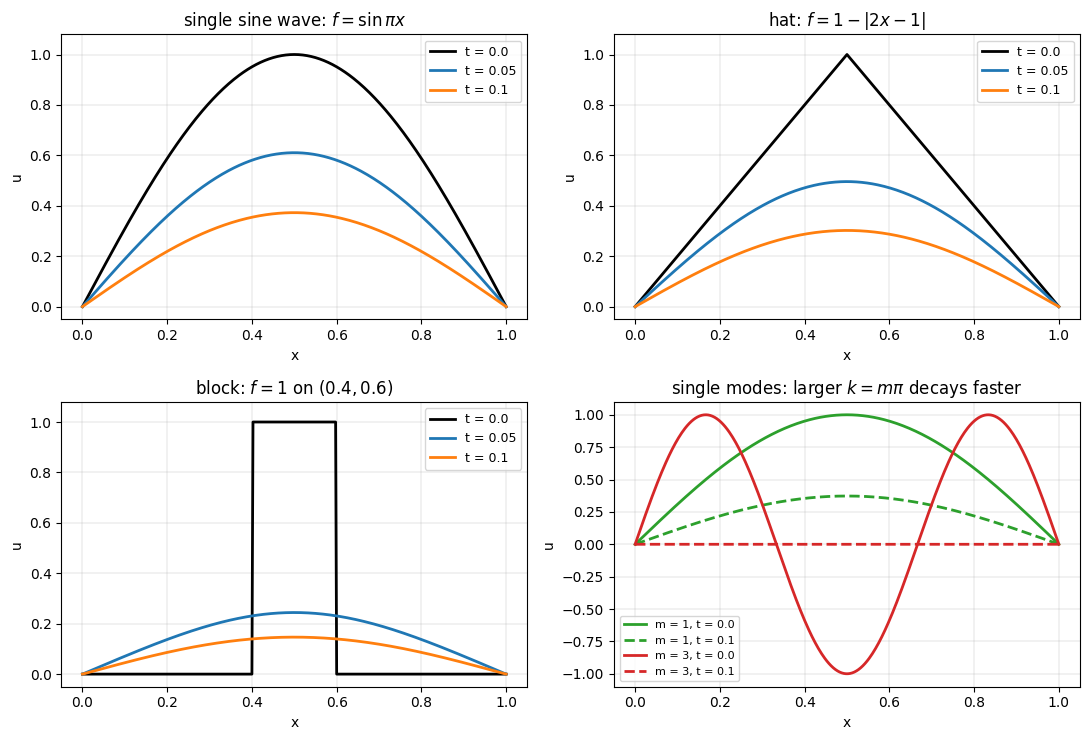

In [ ]:
# Exact (series) solutions of u_t = alpha u_xx on [0, 1] with u(0,t) = u(1,t) = 0
def exact_sin(x, t, alpha=1.0):
    "Initial condition sin(pi x): a single mode, m = 1."
    return np.exp(-alpha*np.pi**2*t)*np.sin(np.pi*x)

def exact_hat(x, t, alpha=1.0, M=400):
    "Initial condition: hat 1 - |2x - 1|. Sum of the first M sine modes."
    m = np.arange(1, M+1)[:, None]                     # column of mode numbers
    bm = 8*np.sin(m*np.pi/2)/(m*np.pi)**2               # Fourier sine coefficients
    return np.sum(bm*np.exp(-alpha*(m*np.pi)**2*t)*np.sin(m*np.pi*x[None, :]), axis=0)

def exact_box(x, t, a=0.4, b=0.6, alpha=1.0, M=2000):
    "Initial condition: u = 1 on (a, b), 0 elsewhere. Sum of the first M sine modes."
    m = np.arange(1, M+1)[:, None]
    bm = 2*(np.cos(m*np.pi*a) - np.cos(m*np.pi*b))/(m*np.pi)
    return np.sum(bm*np.exp(-alpha*(m*np.pi)**2*t)*np.sin(m*np.pi*x[None, :]), axis=0)

# The initial profiles themselves (also used later as starting values for the numerical schemes)
hat = lambda x: 1 - np.abs(2*x - 1)
box = lambda x: np.where((x > 0.4) & (x < 0.6), 1.0, 0.0)

xf = np.linspace(0, 1, 401)
times = [0.0, 0.05, 0.1]
cases = [("single sine wave: $f=\\sin\\pi x$", lambda x: np.sin(np.pi*x), exact_sin),
         ("hat: $f=1-|2x-1|$", hat, exact_hat),
         ("block: $f=1$ on $(0.4, 0.6)$", box, exact_box)]

fig, axs = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (title, f, exact) in zip(axs.flat[:3], cases):
    for t, c in zip(times, ["k", "C0", "C1"]):
        u = f(xf) if t == 0 else exact(xf, t)           # at t = 0 plot the profile itself
        ax.plot(xf, u, color=c, lw=2, label=f"t = {t}")
        ax.grid(True, lw=0.25)
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylabel("u"); ax.set_ylim(-0.05, 1.08); ax.legend(fontsize=9)

ax.grid(True, lw=0.25)
ax = axs[1, 1]                                          # single modes m = 1 and m = 3
for m, c in [(1, "C2"), (3, "C3")]:
    for t, ls in [(0.0, "-"), (0.1, "--")]:
        ax.grid(True, lw=0.25)
        ax.plot(xf, np.exp(-(m*np.pi)**2*t)*np.sin(m*np.pi*xf), color=c, ls=ls, lw=2,
                label=f"m = {m}, t = {t}")
ax.set_title("single modes: larger $k = m\\pi$ decays faster"); ax.set_xlabel("x"); ax.set_ylabel("u")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

**Observations**

* All three profiles keep $u=0$ at the ends and decay with time
  
* The **single sine wave** keeps its shape and only shrinks

* The **hat** loses its sharp corner, and the **block** loses its jumps at once.

* Corners and jumps are made of short waves (large $k$), and these die first.

* So diffusion acts as a **filter that removes short waves first**.

This is the behaviour a good numerical scheme must reproduce, and what the von Neumann analysis will check.

### 1.3 Solving Numerically: Discretizing the domain: the space–time grid

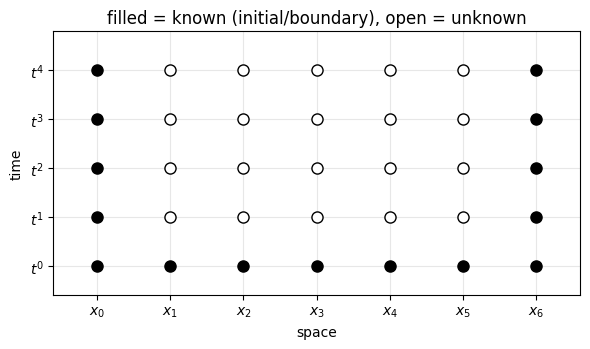

In [ ]:
def draw_grid(ax, scheme=None, N=6, nt=4):
    "Space-time grid; optionally highlight the stencil of FTCS, BTCS or CN at (i=3, n=2 -> 3)."
    for n in range(nt+1):
        for i in range(N+1):
            known = (n == 0) or (i == 0) or (i == N)
            ax.plot(i, n, "o", ms=8, mfc="k" if known else "w", mec="k")
    ax.set_xticks(range(N+1)); ax.set_xticklabels([f"$x_{i}$" for i in range(N+1)])
    ax.set_yticks(range(nt+1)); ax.set_yticklabels([f"$t^{n}$" for n in range(nt+1)])
    ax.set_xlim(-0.6, N+0.6); ax.set_ylim(-0.6, nt+0.8); ax.grid(alpha=0.3)
    i0, n0 = 3, 2
    old = {"FTCS": [(i0-1, n0), (i0, n0), (i0+1, n0)], "BTCS": [(i0, n0)],
           "CN": [(i0-1, n0), (i0, n0), (i0+1, n0)]}
    new = {"FTCS": [(i0, n0+1)], "BTCS": [(i0-1, n0+1), (i0, n0+1), (i0+1, n0+1)],
           "CN": [(i0-1, n0+1), (i0, n0+1), (i0+1, n0+1)]}
    if scheme:
        for (i, n) in old[scheme]: ax.plot(i, n, "s", ms=13, mfc="none", mec="tab:blue", mew=2)
        for (i, n) in new[scheme]: ax.plot(i, n, "s", ms=13, mfc="none", mec="tab:red", mew=2)
        pts = old[scheme] + new[scheme]
        for (i, n) in pts:
            if (i, n) != (i0, n0+1): ax.plot([i, i0], [n, n0+1], color="gray", lw=1, zorder=0)
        ax.set_title(f"{scheme}: blue = known level $t^n$, red = new level $t^{{n+1}}$")
    else:
        ax.set_title("filled = known (initial/boundary), open = unknown")

fig, ax = plt.subplots(figsize=(6, 3.6)); draw_grid(ax); ax.set_xlabel("space"); ax.set_ylabel("time")
plt.tight_layout(); plt.show()

* Space: $x_i=i\,\Delta x$, $i=0,1,\dots,N$, with $\Delta x=L/N$.
* Time: $t^n=n\,\Delta t$, $n=0,1,2,\dots$
* Numerical solution: $u_i^n\approx u(x_i,t^n)$ (subscript = space, superscript = time).
* Known values: the bottom row ($n=0$, initial condition) and the two side columns ($i=0$ and $i=N$, boundary conditions).
* Unknown values: all interior points at later times, found **one time level after another**.

### 1.4 Finite-difference schemes

From Taylor series (numerical differentiation):
$$\frac{\partial u}{\partial t}\Big|_i^n\approx\frac{u_i^{n+1}-u_i^n}{\Delta t}\ \ (\text{forward},\ O(\Delta t))$$

$$\frac{\partial^2 u}{\partial x^2}\Big|_i^n\approx\frac{u_{i+1}^n-2u_i^n+u_{i-1}^n}{\Delta x^2}\ \ (\text{central},\ O(\Delta x^2)).$$

#### FTCS — Forward in Time, Central in Space (explicit)
$$\frac{u_i^{n+1}-u_i^n}{\Delta t}=\alpha\,\frac{u_{i+1}^n-2u_i^n+u_{i-1}^n}{\Delta x^2}
\quad\Longrightarrow\quad
\boxed{u_i^{n+1}=u_i^n+r\left(u_{i+1}^n-2u_i^n+u_{i-1}^n\right)}$$

where,
$$\boxed{r=\frac{\alpha\,\Delta t}{\Delta x^2}}$$

* $r$ is the **diffusion number** (in heat transfer also called the **mesh Fourier number**) is always positive
* It compares the time step with the time heat needs to diffuse across one grid cell, $\Delta x^2/\alpha$
* **This is called an explicit scheme**: Unknown value (left) is computed directly from known values (right)

#### BTCS — Backward in Time, Central in Space (implicit)
Evaluate the space derivative at the **new** time level $n+1$:
$$\frac{u_i^{n+1}-u_i^n}{\Delta t}=\alpha\,\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}
\quad\Longrightarrow\quad
\boxed{-r\,u_{i-1}^{n+1}+(1+2r)\,u_i^{n+1}-r\,u_{i+1}^{n+1}=u_i^n}$$

* **This is called an implicit scheme**:
* Three unknowns appear in each equation, so all interior values at $t^{n+1}$ are coupled.
* A tridiagonal linear system of equations must be solved at every time step.

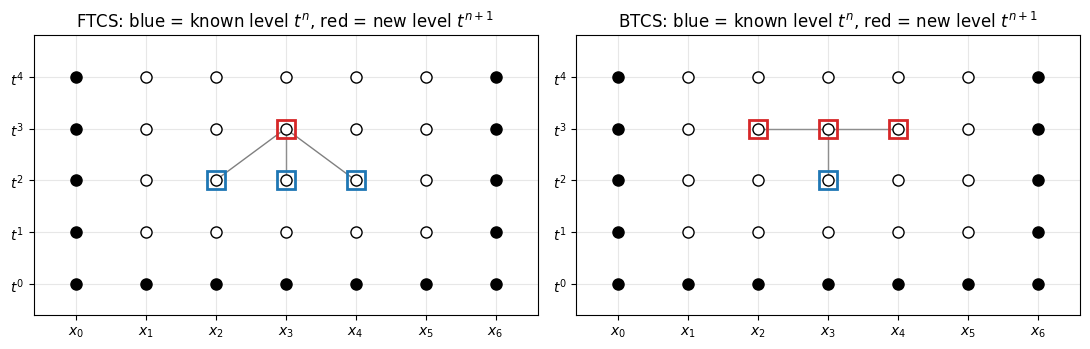

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
draw_grid(ax[0], "FTCS"); draw_grid(ax[1], "BTCS")
plt.tight_layout(); plt.show()

### 1.5 Local (truncation) error and global error

**Local truncation error $\tau$**

Insert the *exact* solution into the scheme and see what remains: the leftover is the truncation error.

For FTCS, expanding $u(x_i,t^{n+1})$ and $u(x_{i\pm1},t^n)$ in Taylor series about $(x_i,t^n)$:
$$\tau_i^n=\frac{u(x_i,t^{n+1})-u(x_i,t^n)}{\Delta t}-\alpha\frac{u(x_{i+1},t^n)-2u(x_i,t^n)+u(x_{i-1},t^n)}{\Delta x^2}
=\underbrace{\frac{\Delta t}{2}u_{tt}}_{\text{time}}-\underbrace{\frac{\alpha\Delta x^2}{12}u_{xxxx}}_{\text{space}}+\dots
=O(\Delta t)+O(\Delta x^2).$$

* FTCS and BTCS are both **first order in time** and **second order in space**.
* For BTCS the time term changes sign: $\tau=-\frac{\Delta t}{2}u_{tt}-\frac{\alpha\Delta x^2}{12}u_{xxxx}+\dots$
* A neat consequence. For the heat equation $u_{tt}=\alpha^2u_{xxxx}$, so
$$\tau_{\rm FTCS}=\frac{\alpha\Delta x^2}{2}\Big(r-\frac16\Big)u_{xxxx}+\dots$$
  With $r=1/6$ the leading FTCS errors **cancel**, and $\tau$ drops to $O(\Delta x^4)$.

**Local error vs global error**
* **Local error**: the error made in **one** step if we started from exact values, $\Delta t\cdot\tau=O(\Delta t^2)+O(\Delta t\,\Delta x^2)$.
* **Global error** $e_i^n=u(x_i,t^n)-u_i^n$: what we actually see after $n$ steps.
* The local errors of all $N_t=T/\Delta t$ steps accumulate:
$$\text{global error}\approx\frac{T}{\Delta t}\times\big[O(\Delta t^2)+O(\Delta t\,\Delta x^2)\big]=O(\Delta t)+O(\Delta x^2).$$
* The global error is **one order lower in $\Delta t$** than the local error, because the errors of many steps add up.
* It has the **same order as the truncation error $\tau$**, which is why we call FTCS "first order in time".
* This accumulation argument only works if the scheme does **not amplify** earlier errors.
* We discuss exactly this later, in the section on **stability**.

### 1.4 Example: One-dimensional metal rod solved with FTCS

* Domain $x\in[0,L]$, $L=1$, $\alpha=1$ (dimensionless).
* Initial condition: $u(x,0)=f(x)=\sin(\pi x)$.
* Boundary conditions (Dirichlet): $u(0,t)=0$, $u(L,t)=0$.
* Exact solution: $u(x,t)=e^{-\pi^2t}\sin(\pi x)$.

**Matrix view of FTCS.** Collect the interior values $\mathbf u^n=[u_1^n,\dots,u_{N-1}^n]^T$:
$$\mathbf u^{n+1}=(I-rK)\,\mathbf u^n,\qquad K=\mathrm{tridiag}(-1,\,2,\,-1).$$
FTCS is **explicit**: each step is only a matrix–vector multiplication, so no linear system is solved here.

**Pseudo-algorithm (FTCS)**
```text
input : N, dt, T, alpha, initial condition f, boundary values
dx = L/N ;  r = alpha*dt/dx^2 ;  nt = T/dt
u[i] = f(x_i)  for i = 0..N ;  apply boundary conditions
for n = 1 .. nt:
    for i = 1 .. N-1:
        u_new[i] = u[i] + r*(u[i+1] - 2*u[i] + u[i-1])
    apply boundary conditions to u_new   (u_new[0] = g0, u_new[N] = gL)
    u = u_new
```

#### Python implementation (simple version)
Close to the pseudo-algorithm

dx = 0.1,  dt = 0.002,  diffusion number r = 0.200


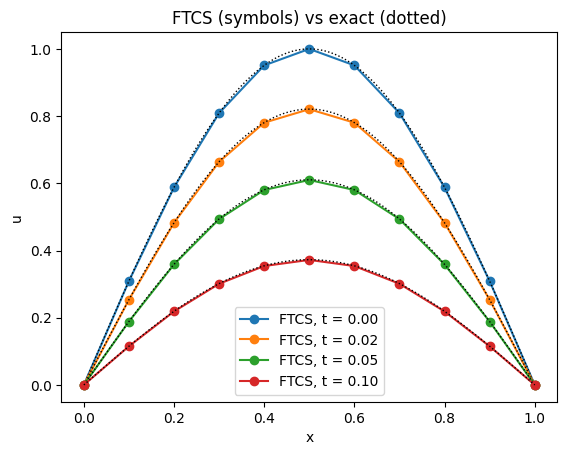

max error at t = 0.1: 6.03e-04


In [ ]:
def ftcs_simple(N, dt, nt, alpha=1.0, L=1.0):
    x = np.linspace(0, L, N+1)
    dx = L/N
    r = alpha*dt/dx**2
    U = np.zeros((nt+1, N+1))
    U[0, :] = np.sin(np.pi*x/L)        # initial condition
    U[:, 0] = 0.0; U[:, -1] = 0.0      # boundary conditions
    for n in range(nt):
        for i in range(1, N):
            U[n+1, i] = U[n, i] + r*(U[n, i+1] - 2*U[n, i] + U[n, i-1])
    return x, U, r

N, dt, nt = 10, 0.002, 50
x, U, r = ftcs_simple(N, dt, nt)
print(f"dx = {1/N},  dt = {dt},  diffusion number r = {r:.3f}")

for n in [0, 10, 25, 50]:
    plt.plot(x, U[n], "o-", label=f"FTCS, t = {n*dt:.2f}")
    plt.plot(xf, exact_sin(xf, n*dt), "k:", lw=1)
plt.xlabel("x"); plt.ylabel("u"); plt.title("FTCS (symbols) vs exact (dotted)"); plt.legend(); plt.show()
print(f"max error at t = 0.1: {np.max(np.abs(U[-1] - exact_sin(x, nt*dt))):.2e}")

#### Python implementation (vectorized version)
* The interior update in one line with array slices: `u[1:-1] + r*(u[2:] - 2*u[1:-1] + u[:-2])`
* We choose $r$ and compute $\Delta t=r\Delta x^2/\alpha$

In [ ]:
def ftcs(f, N, r, T, alpha=1.0, L=1.0, nsave=80):
    x = np.linspace(0, L, N+1); dx = L/N
    nt = int(np.ceil(T/(r*dx**2/alpha))); dt = T/nt; r = alpha*dt/dx**2
    u = f(x).astype(float); u[0] = u[-1] = 0.0
    save = set(np.linspace(0, nt, min(nsave, nt+1)).astype(int))
    ts, Us = [0.0], [u.copy()]
    for n in range(1, nt+1):
        u[1:-1] = u[1:-1] + r*(u[2:] - 2*u[1:-1] + u[:-2])
        if n in save: ts.append(n*dt); Us.append(u.copy())
    return x, np.array(ts), np.array(Us), r

# you can check: same result as the simple version (r = 0.2, T = 0.1)
x2, ts, Us, r2 = ftcs(lambda x: np.sin(np.pi*x), 10, 0.2, 0.1)
print("max difference from ftcs_simple:", np.max(np.abs(Us[-1] - U[-1])))

max difference from ftcs_simple: 0.0


### 1.5 Do it yourself: experiment with $\Delta x$, $\Delta t$ and the diffusion number $r$

Use the explorer below to experiment with $\Delta x$, $\Delta t$ and the diffusion number $r$

As suggestions, you may:
* Keep $r=0.2$ and refine the grid ($N=10\to20\to40$). How does the error change?
* Keep $N=20$ and increase $r$ slowly: $0.3,\ 0.45,\ 0.5,\ 0.52,\ 0.6$. What happens above $r=0.5$?
* Switch to the **hat** initial condition (it contains short waves) and repeat.
* Try $r=1/6\approx0.167$ with the sine initial condition and compare the error with $r=0.15$ and $r=0.2$.

In [ ]:
def explore_ftcs(N=20, r=0.4, T=0.05, initial="sin"):
    f, ex = (lambda x: np.sin(np.pi*x), exact_sin) if initial == "sin" else (hat, exact_hat)
    x, ts, Us, r_used = ftcs(f, N, r, T)
    err = np.max(np.abs(Us[-1] - ex(x, T)))
    plt.figure(figsize=(7, 4))
    plt.plot(xf, ex(xf, T), "k-", lw=1.5, label="exact")
    plt.plot(x, Us[-1], "o-", color="tab:red", label="FTCS")
    plt.plot(xf, f(xf), color="gray", ls=":", label="initial")
    lim = max(1.1, 1.1*min(np.max(np.abs(Us[-1])), 50))
    plt.ylim(-lim, lim)
    plt.title(f"N = {N}, dx = {1/N:.3f}, dt = {r_used/N**2:.2e}, r = {r_used:.3f}, steps = {round(T*N**2/r_used)}\n"
              f"max error at T = {T}: {err:.2e}")
    plt.xlabel("x"); plt.ylabel("u"); plt.legend(); plt.show()

interact(explore_ftcs, N=IntSlider(value=20, min=5, max=60, step=5),
         r=FloatSlider(value=0.4, min=0.05, max=0.7, step=0.01, readout_format=".2f"),
         T=FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01),
         initial=Dropdown(options=["sin", "hat"], value="sin"));

interactive(children=(IntSlider(value=20, description='N', max=60, min=5, step=5), FloatSlider(value=0.4, desc…

In [ ]:
# Animation: FTCS with the hat initial condition, just below and just above r = 1/2
N, T = 20, 0.06
runs = {r: ftcs(hat, N, r, T, nsave=60) for r in [0.48, 0.55]}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
lines = []
for ax, (r, (x, ts, Us, ru)) in zip(axs, runs.items()):
    le, = ax.plot(xf, exact_hat(xf, 0), "k-", lw=1.2, label="exact")
    ln, = ax.plot(x, Us[0], "o-", color="tab:red", ms=4, label="FTCS")
    ax.set_ylim(-0.6, 1.1); ax.set_xlabel("x"); ax.legend(loc="upper right"); lines.append((ax, le, ln, ts, Us, ru))
def update(k):
    out = []
    for ax, le, ln, ts, Us, ru in lines:
        kk = min(k, len(ts)-1)
        le.set_ydata(exact_hat(xf, ts[kk])); ln.set_ydata(Us[kk])
        ax.set_title(f"r = {ru:.3f},  t = {ts[kk]:.4f}"); out += [le, ln]
    return out
anim = FuncAnimation(fig, update, frames=60, interval=120, blit=False)
plt.close(fig); HTML(anim.to_jshtml())

Why one solution for specific value of $r$ is well behaved vs. other vary so widely?

### Observations: FTCS
* **$r\le\tfrac12$:** the numerical solution follows the exact one; the error falls by about 4 when $\Delta x$ is halved at fixed $r$
* **$r>\tfrac12$:** a **zig-zag (saw-tooth) pattern** appears, flips sign every step, and grows without bound. It starts where short waves are present (the corner of the hat)
* **Refining the grid can make things worse.**
* $r=1/6$ is special
* FTCS is accurate but only **conditionally stable**

### 1.6 BTCS: solving a linear system at every time step

Writing the BTCS equation for $i=1,\dots,N-1$ (with boundary conditions $u_0^{n+1}=g_0$, $u_N^{n+1}=g_L$):

$$\underbrace{\begin{bmatrix}1+2r&-r&&\\-r&1+2r&-r&\\&\ddots&\ddots&\ddots\\&&-r&1+2r\end{bmatrix}}_{A=I+rK}
\begin{bmatrix}u_1^{n+1}\\u_2^{n+1}\\\vdots\\u_{N-1}^{n+1}\end{bmatrix}
=\begin{bmatrix}u_1^{n}+r\,g_0\\u_2^{n}\\\vdots\\u_{N-1}^{n}+r\,g_L\end{bmatrix}$$

**Observe some important properties of $A$**
* Symmetric and tridiagonal
* Sparse: at most 3 non-zeros per row
* Strictly diagonally dominant
* Symmetric positive definite
* $A$ is the **same at every time step**; only the right-hand side changes.

**How to solve it: directly or iteratively**
* **Jacobi iteration** converges for every $r$ (strict diagonal dominance).
* Jacobi iteration matrix:
* $T_J=-D^{-1}(L+U)=\dfrac{r}{1+2r}\,\mathrm{tridiag}(1,0,1)$
* The spectral radius of the Jacobi iteration matrix is
* $\rho_J=\dfrac{2r\cos(\pi\Delta x)}{1+2r}<1$ (for $L=1$)
* So it is fast for small $r$ and slow for large $r$.
* Direct alternative: the **Thomas algorithm** (tridiagonal LU), $O(N)$ operations

**Pseudo-algorithm (BTCS with Jacobi inner iterations)**
```text
for n = 0 .. nt-1:                                # time steps
    b[i] = u^n[i]                for i = 1..N-1   # right-hand side (old values)
    v = copy of u^n                               # initial guess for u^{n+1}
    v[0] = g0 ;  v[N] = gL                        # boundary values at the new time t^{n+1}
    repeat:                                       # Jacobi sweeps
        v_new[i] = ( b[i] + r*(v[i-1] + v[i+1]) ) / (1 + 2r)    for i = 1..N-1
        (v_new[0] = g0 and v_new[N] = gL stay fixed)
        stop if max|v_new - v| < tol
        v = v_new
    u^{n+1} = v_new
```

In [ ]:
def btcs_jacobi(N, r, nt, alpha=1.0, L=1.0, tol=1e-10, max_sweeps=10000):
    x = np.linspace(0, L, N+1)
    U = np.zeros((nt+1, N+1)); U[0] = np.sin(np.pi*x/L)
    sweeps = []
    for n in range(nt):
        b = U[n].copy()                      # boundary values are 0 here, so b = u^n
        v = U[n].copy()                      # initial guess
        for k in range(1, max_sweeps+1):
            v_new = v.copy()
            for i in range(1, N):
                v_new[i] = (b[i] + r*(v[i-1] + v[i+1]))/(1 + 2*r)
            if np.max(np.abs(v_new - v)) < tol:
                break
            v = v_new
        U[n+1] = v_new; sweeps.append(k)
    return x, U, np.array(sweeps)

N, r, T = 20, 2.0, 0.1
dt = r*(1/N)**2; nt = int(round(T/dt))
x, U, sweeps = btcs_jacobi(N, r, nt)
print(f"N = {N}, r = {r} (four times the FTCS limit), dt = {dt}, steps = {nt}")
print(f"Jacobi sweeps per time step: {sweeps.min()} to {sweeps.max()}")
print(f"max error at t = {nt*dt:.3f}: {np.max(np.abs(U[-1] - exact_sin(x, nt*dt))):.2e}")

N = 20, r = 2.0 (four times the FTCS limit), dt = 0.005000000000000001, steps = 20
Jacobi sweeps per time step: 76 to 80
max error at t = 0.100: 9.63e-03


#### A BTCS solver (direct tridiagonal solve)

`scipy.linalg.solve_banded` solves the tridiagonal system directly (banded LU from LAPACK, $O(N)$ work), which is how BTCS is normally coded in 1D.

In [ ]:
def btcs(f, N, r, T, alpha=1.0, L=1.0, nsave=80):
    x = np.linspace(0, L, N+1); dx = L/N
    nt = int(np.ceil(T/(r*dx**2/alpha))); dt = T/nt; r = alpha*dt/dx**2
    n = N - 1
    ab = np.zeros((3, n)); ab[0, 1:] = -r; ab[1, :] = 1 + 2*r; ab[2, :-1] = -r   # A = I + rK
    u = f(x).astype(float); u[0] = u[-1] = 0.0
    save = set(np.linspace(0, nt, min(nsave, nt+1)).astype(int))
    ts, Us = [0.0], [u.copy()]
    for k in range(1, nt+1):
        u[1:-1] = solve_banded((1, 1), ab, u[1:-1])
        if k in save: ts.append(k*dt); Us.append(u.copy())
    return x, np.array(ts), np.array(Us), r

x2, ts, Us, r2 = btcs(lambda x: np.sin(np.pi*x), 20, 2.0, 0.1)
print("max difference between Jacobi and direct BTCS:", np.max(np.abs(Us[-1] - U[-1])))

max difference between Jacobi and direct BTCS: 4.412588017199681e-09


In [ ]:
# Animation: FTCS vs BTCS with the same time step, hat initial condition
N, T, r = 20, 0.06, 0.4
xa, tsa, Ua, ra = ftcs(hat, N, r, T, nsave=60)
xb, tsb, Ub, rb = btcs(hat, N, r, T, nsave=60)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
items = []
for ax, name, xx, ts, UU in [(axs[0], "FTCS", xa, tsa, Ua), (axs[1], "BTCS", xb, tsb, Ub)]:
    le, = ax.plot(xf, exact_hat(xf, 0), "k-", lw=1.2, label="exact")
    ln, = ax.plot(xx, UU[0], "o-", ms=4, color="tab:red" if name == "FTCS" else "tab:blue", label=name)
    ax.set_ylim(-0.6, 1.1); ax.set_xlabel("x"); ax.legend(loc="upper right"); items.append((ax, name, le, ln, ts, UU))
def update(k):
    out = []
    for ax, name, le, ln, ts, UU in items:
        kk = min(k, len(ts)-1); le.set_ydata(exact_hat(xf, ts[kk])); ln.set_ydata(UU[kk])
        ax.set_title(f"{name}, r = {r},  t = {ts[kk]:.4f}"); out += [le, ln]
    return out
anim = FuncAnimation(fig, update, frames=60, interval=120); plt.close(fig); HTML(anim.to_jshtml())

* Change the value of $r$ and compare the solutions. Particularly when FTCS becomes unstable.
* Due you find BTCS always stable irrespective to the value of $r$?

In [ ]:
# Accuracy and Jacobi effort of BTCS as the time step grows (N = 20, T = 0.1)
N, T = 20, 0.1
print(f"{'r':>6} {'dt':>9} {'steps':>6} {'Jacobi sweeps/step':>19} {'rho_J':>7} {'max error':>10}")
for r in [0.25, 0.5, 2.0, 10.0, 40.0]:
    dt = r/N**2; nt = int(round(T/dt))
    x, U, sw = btcs_jacobi(N, r, nt)
    rhoJ = 2*r*np.cos(np.pi/N)/(1 + 2*r)
    print(f"{r:6.2f} {dt:9.5f} {nt:6d} {sw.mean():19.1f} {rhoJ:7.3f} {np.max(np.abs(U[-1]-exact_sin(x, nt*dt))):10.2e}")

     r        dt  steps  Jacobi sweeps/step   rho_J  max error
  0.25   0.00063    160                16.9   0.329   1.89e-03
  0.50   0.00125     80                26.3   0.494   3.01e-03
  2.00   0.00500     20                77.7   0.790   9.63e-03
 10.00   0.02500      4               299.8   0.941   4.19e-02
 40.00   0.10000      1               752.0   0.975   1.31e-01


### Observations: BTCS
* BTCS **never blows up**: it stays smooth and bounded for any $r$ (even $r=40$, i.e. 80 times the FTCS limit).
* **Stable is not the same as accurate.** The error grows with $\Delta t$ (first order in time)
* Each step costs a linear solve. With Jacobi, the number of sweeps per step grows with $r$
* A direct tridiagonal solve costs $O(N)$ regardless of $r$
* Trade-off:
    * FTCS = cheap steps but $\Delta t\le\Delta x^2/(2\alpha)$;
    * BTCS = more work per step but any $\Delta t$ but we need to check *accuracy*.

### 1.7 Concepts: Consistency, stability and convergence

These three concepts in numerical methods for solving PDEs come straight out of the observations above.

* **Consistency**:
    * Ask whether the finite-difference scheme is consistent with the original continuous PDE.
    * Check how the difference equation approaches the PDE as the grid is refined, i.e. the truncation error $\tau\to0$ as $\Delta x,\Delta t\to0$.
    * We are trying to check: *Does the finite-difference scheme solve the right equation?*

* **Stability**:
    * Is the scheme stable?
    * Do errors (round-off, truncation, errors in the initial data) stay bounded, or are they **amplified without bound** as we march in time?
    * $\|\mathbf u^n\|\le C\,\|\mathbf u^0\|$ for $0\le n\Delta t\le T$, with $C$ independent of $\Delta x,\Delta t$. For a linear scheme the error obeys the same scheme, so the same bound holds for the error.
    * *Do small errors stay small?*

* **Convergence**:
    * Does the numerical solution approach the exact solution?
    * $\max_i|u_i^n-u(x_i,t^n)|\to0$ as $\Delta x,\Delta t\to0$.
    * *Do we get the right answer when the PDE is solved numerically?*

> **Lax equivalence theorem.**
> * For a well-posed **linear** PDE problem, a consistent (linear) finite-difference scheme is convergent if and only if it is stable:
> * consistency + **stability $\iff$ convergence**.
> * Consistency is usually easy to check (Taylor series), so the real work is checking **stability**.

#### Are FTCS and BTCS consistent?
Insert the exact solution $u=e^{-\pi^2t}\sin\pi x$ into each scheme on finer and finer grids, keeping $r$ fixed, and evaluate the leftover $\tau$. If $\tau\to0$, the scheme is consistent.

FTCS, r = 0.100: tau = 2.0e-02  5.0e-03  1.2e-03  3.1e-04  7.7e-05   order ~ 2.0
FTCS, r = 0.167: tau = 1.1e-04  6.8e-06  4.2e-07  2.7e-08  1.7e-09   order ~ 4.0
FTCS, r = 0.400: tau = 6.8e-02  1.7e-02  4.3e-03  1.1e-03  2.7e-04   order ~ 2.0
FTCS, r = 0.600: tau = 1.3e-01  3.2e-02  8.0e-03  2.0e-03  5.0e-04   order ~ 2.0
BTCS, r = 0.400: tau = 1.6e-01  4.2e-02  1.1e-02  2.6e-03  6.6e-04   order ~ 2.0
BTCS, r = 2.000: tau = 5.6e-01  1.6e-01  4.0e-02  1.0e-02  2.5e-03   order ~ 2.0


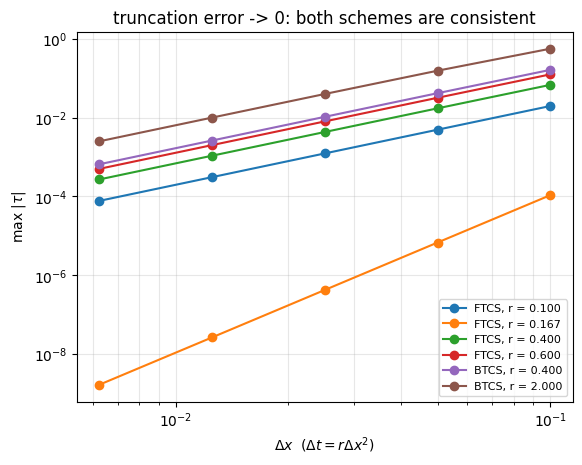

In [ ]:
def tau_max(N, r, scheme, t=0.05):
    dx = 1/N; dt = r*dx**2
    x = np.linspace(0, 1, N+1); i = np.arange(1, N)
    u0, u1 = exact_sin(x, t), exact_sin(x, t + dt)
    lap = lambda u: (u[i+1] - 2*u[i] + u[i-1])/dx**2
    if scheme == "FTCS": tau = (u1[i] - u0[i])/dt - lap(u0)
    else:                tau = (u1[i] - u0[i])/dt - lap(u1)
    return np.max(np.abs(tau))

Ns = [10, 20, 40, 80, 160]
for scheme, rs in [("FTCS", [0.1, 1/6, 0.4, 0.6]), ("BTCS", [0.4, 2.0])]:
    for r in rs:
        taus = [tau_max(N, r, scheme) for N in Ns]
        orders = np.log2(np.array(taus[:-1])/np.array(taus[1:]))
        print(f"{scheme}, r = {r:5.3f}: tau = " + "  ".join(f"{v:.1e}" for v in taus) + f"   order ~ {orders[-1]:.1f}")
        plt.loglog([1/N for N in Ns], taus, "o-", label=f"{scheme}, r = {r:.3f}")
plt.xlabel(r"$\Delta x$  ($\Delta t = r\Delta x^2$)"); plt.ylabel(r"max $|\tau|$"); plt.legend(fontsize=8)
plt.grid(alpha=0.3, which="both"); plt.title("truncation error -> 0: both schemes are consistent"); plt.show()

**Observations**
* For every $r$ the truncation error of both schemes goes to zero like $\Delta x^2$ (order 2): **FTCS and BTCS are both consistent.**
* At $r=1/6$ the FTCS truncation error is much smaller and falls like $\Delta x^4$ (leading terms cancel).

FTCS, r = 0.4     : 4.29e-03  1.06e-03  2.65e-04  6.62e-05
FTCS, r = 0.6     : 7.83e-03  1.96e-03  3.55e+21  5.20e+138
BTCS, r = 0.4     : 1.01e-02  2.56e-03  6.42e-04  1.61e-04
BTCS, dt = dx/10  : 2.03e-02  9.63e-03  4.68e-03  2.30e-03


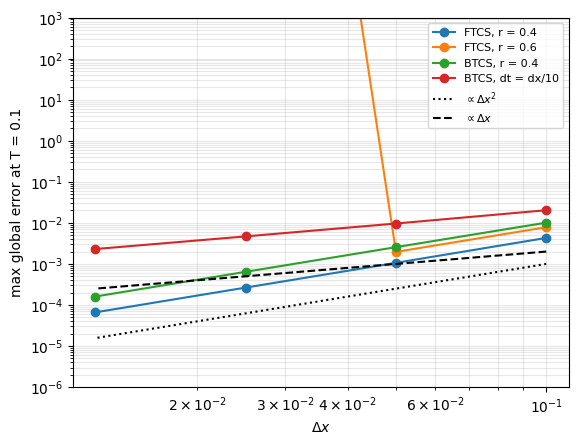

In [ ]:
# Convergence study (global error at total time, T = 0.1)
Ns = [10, 20, 40, 80]
cases = [("FTCS, r = 0.4", lambda N: ftcs(lambda x: np.sin(np.pi*x), N, 0.4, 0.1)),
         ("FTCS, r = 0.6", lambda N: ftcs(lambda x: np.sin(np.pi*x), N, 0.6, 0.1)),
         ("BTCS, r = 0.4", lambda N: btcs(lambda x: np.sin(np.pi*x), N, 0.4, 0.1)),
         ("BTCS, dt = dx/10", lambda N: btcs(lambda x: np.sin(np.pi*x), N, 0.1*N, 0.1))]
for name, run in cases:
    errs = []
    for N in Ns:
        x, ts, Us, r = run(N); errs.append(np.max(np.abs(Us[-1] - exact_sin(x, 0.1))))
    print(f"{name:18s}: " + "  ".join(f"{e:.2e}" for e in errs))
    plt.loglog([1/N for N in Ns], errs, "o-", label=name)
plt.loglog([1/N for N in Ns], [0.1/N**2 for N in Ns], "k:", label=r"$\propto\Delta x^2$")
plt.loglog([1/N for N in Ns], [0.02/N for N in Ns], "k--", label=r"$\propto\Delta x$")
plt.ylim(1e-6, 1e3); plt.xlabel(r"$\Delta x$"); plt.ylabel("max global error at T = 0.1"); plt.legend(fontsize=8)
plt.grid(alpha=0.3, which="both"); plt.show()

**Observations**
* FTCS, $r=0.4$ and BTCS, $r=0.4$: the global error decreases like $\Delta x^2$ — both **converge**.
* FTCS, $r=0.6$: on the two coarsest grids the answer still looks fine (few steps, so the round-off seed has not grown yet),
* But at $N=40$ the error is $10^{21}$ and at $N=80$ $10^{138}$ — **no convergence**, although the scheme is consistent.
* BTCS with $\Delta t=\Delta x/10$ (time step shrinking only like $\Delta x$): the error decreases only like $\Delta x$, because the $O(\Delta t)$ time error dominates. The global error inherits the order of the truncation error.

### 1.7 Von Neumann stability analysis

1. **Any grid function is a sum of waves.** On a grid with spacing $\Delta x$, any profile (and any error) can be written as a sum of discrete waves $e^{\,\mathrm j k x_i}$, $\mathrm j=\sqrt{-1}$. Since $x_i=i\Delta x$, we have $kx_i=i\,\theta$, so only the phase change per grid cell matters, $\theta=k\Delta x\in[0,\pi]$:
    * $\theta$ small: a long, smooth wave,
    * $\theta=\pi$: the shortest wave the grid can show — the **zig-zag** $+1,-1,+1,\dots$
2. **A linear scheme treats every wave separately.** With constant coefficients, one time step simply multiplies each wave by a number, the **amplification factor** $G(\theta)$:
   $$u_i^n=G^n\,e^{\,\mathrm j\, i\theta}.$$
3. **In the exact PDE solution**, each wave decays by $e^{-\alpha k^2\Delta t}=e^{-r\theta^2}$ per time step $\Delta t$ (because $\alpha k^2\Delta t=\frac{\alpha\Delta t}{\Delta x^2}(k\Delta x)^2=r\theta^2$): a number between 0 and 1.
4. **Stability condition.** No wave may grow:
   $$\boxed{|G(\theta)|\le1\quad\text{for all }\theta\in[0,\pi]}$$
   If even one wave has $|G|>1$, round-off excites it and it grows like $|G|^n$.

Let us first *measure* $G$ numerically: start FTCS from a single wave $\sin(m\pi x_i)$, take **one** step, and compute the ratio new/old.

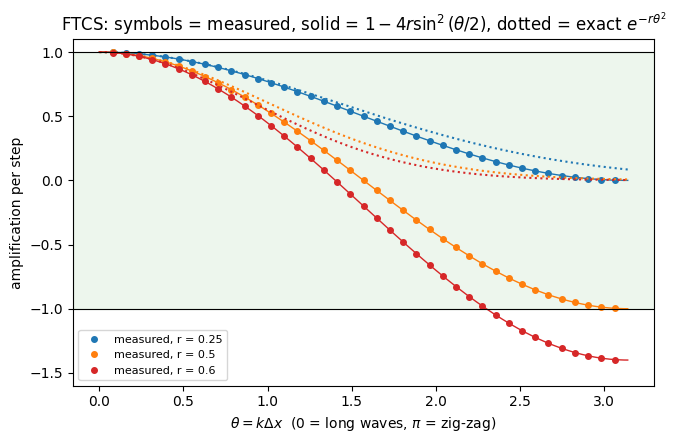

In [ ]:
def measured_G(r, N=40, scheme="FTCS"):
    thetas, Gs = [], []
    x = np.linspace(0, 1, N+1); dx = 1/N
    for m in range(1, N):
        u0 = np.sin(m*np.pi*x)
        if scheme == "FTCS":
            u1 = u0.copy(); u1[1:-1] = u0[1:-1] + r*(u0[2:] - 2*u0[1:-1] + u0[:-2])
        else:
            ab = np.zeros((3, N-1)); ab[0, 1:] = -r; ab[1, :] = 1 + 2*r; ab[2, :-1] = -r
            u1 = u0.copy(); u1[1:-1] = solve_banded((1, 1), ab, u0[1:-1])
        k = np.argmax(np.abs(u0[1:-1])) + 1               # a node where the wave is not ~0
        thetas.append(m*np.pi*dx); Gs.append(u1[k]/u0[k])
    return np.array(thetas), np.array(Gs)

th = np.linspace(0, np.pi, 300)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for r, c in zip([0.25, 0.5, 0.6], ["C0", "C1", "C3"]):
    tm, Gm = measured_G(r)
    ax.plot(tm, Gm, "o", color=c, ms=4, label=f"measured, r = {r}")
    ax.plot(th, 1 - 4*r*np.sin(th/2)**2, "-", color=c, lw=1)
    ax.plot(th, np.exp(-r*th**2), ":", color=c, lw=1.5)
ax.axhspan(-1, 1, color="green", alpha=0.07); ax.axhline(-1, color="k", lw=0.8); ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel(r"$\theta = k\Delta x$  (0 = long waves, $\pi$ = zig-zag)"); ax.set_ylabel("amplification per step")
ax.set_title("FTCS: symbols = measured, solid = $1-4r\\sin^2(\\theta/2)$, dotted = exact $e^{-r\\theta^2}$")
ax.legend(fontsize=8, loc="lower left"); ax.set_ylim(-1.6, 1.1); plt.show()

**What the plot shows**
* The measured ratios lie exactly on one curve: one step really does multiply each wave by a single number $G(\theta)$.
* Long waves ($\theta\to0$): $G\approx e^{-r\theta^2}\approx1$ — the scheme copies the physics well.
* Short waves: for $r>\tfrac14$, $G$ becomes **negative** (the wave flips sign every step).
    * $r=0.25$: $G\ge0$ for all waves.
    * $r=0.5$: the shortest wave has $G\approx-1$; it flips sign every step but does not grow (the stability limit).
    * $r=0.6$: the shortest wave has $G\approx1-4(0.6)=-1.4$; it flips **and grows** by about 40 % per step. This is exactly the saw-tooth we saw in the FTCS animation.

#### Von Neumann stability analysis of FTCS
Insert $u_i^n=G^n e^{\mathrm j i\theta}$ into $u_i^{n+1}=u_i^n+r(u_{i+1}^n-2u_i^n+u_{i-1}^n)$ and divide by $G^ne^{\mathrm j i\theta}$:

$$G=1+r\left(e^{\mathrm j\theta}-2+e^{-\mathrm j\theta}\right)=1-2r(1-\cos\theta)=\boxed{1-4r\sin^2\frac{\theta}{2}} .$$

* $G$ is real; its largest value is $1$ ($\theta=0$) and its smallest is $1-4r$ ($\theta=\pi$, the zig-zag).
* $|G|\le1$ for all $\theta$ requires $1-4r\ge-1$:
$$\boxed{r=\frac{\alpha\Delta t}{\Delta x^2}\le\frac12\qquad\Longleftrightarrow\qquad \Delta t\le\frac{\Delta x^2}{2\alpha}}$$

#### Von Neumann stability analysis of BTCS
Insert $u_i^n=G^ne^{\mathrm j i\theta}$ into $u_i^{n+1}-r(u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1})=u_i^n$:
$$G\left(1+4r\sin^2\frac\theta2\right)=1\quad\Longrightarrow\quad \boxed{G=\frac{1}{1+4r\sin^2(\theta/2)}}$$
* $0<G\le1$ for **every** $r>0$ and every $\theta$: BTCS is **unconditionally stable**.
* No wave ever flips sign: BTCS profiles never oscillate.
* But for large $r$, $G$ of the long waves is too close to 1 compared with $e^{-r\theta^2}$: they decay too slowly (the first-order time error seen earlier).

In [ ]:
# def plot_G(r=0.6):
#     th = np.linspace(0, np.pi, 300); s = np.sin(th/2)**2
#     plt.figure(figsize=(7.5, 4.2))
#     plt.plot(th, np.exp(-r*th**2), "k-", lw=2, label=r"exact $e^{-r\theta^2}$")
#     plt.plot(th, 1 - 4*r*s, label="FTCS")
#     plt.plot(th, 1/(1 + 4*r*s), label="BTCS")
#     plt.plot(th, (1 - 2*r*s)/(1 + 2*r*s), label="Crank-Nicolson")
#     plt.axhspan(-1, 1, color="green", alpha=0.07); plt.axhline(-1, color="k", lw=0.8)
#     plt.ylim(-2, 1.1); plt.xlabel(r"$\theta=k\Delta x$"); plt.ylabel(r"$G(\theta)$")
#     plt.title(f"amplification factors, r = {r:.2f}   (stable: inside the shaded band)"); plt.legend(fontsize=9); plt.show()

# interact(plot_G, r=FloatSlider(value=0.3, min=0.05, max=5, step=0.05));

**Stability and convergence of FTCS and BTCS**

| scheme | truncation error | von Neumann $G(\theta)$ | stability | convergent (Lax)? |
|---|---|---|---|---|
| FTCS | $O(\Delta t)+O(\Delta x^2)$ | $1-4r\sin^2(\theta/2)$ | conditionally, $r\le\frac12$ | yes, if $r\le\frac12$ |
| BTCS | $O(\Delta t)+O(\Delta x^2)$ | $1/(1+4r\sin^2(\theta/2))$ | unconditionally | yes, for any $r$ |

### 1.8 Crank–Nicolson scheme

* FTCS evaluates the space derivative at $t^n$
* BTCS at $t^{n+1}$.
* Crank–Nicolson takes the **average** (centred at $t^{n+1/2}$ — the trapezoidal rule in time):
  
$$\frac{u_i^{n+1}-u_i^n}{\Delta t}=\frac{\alpha}{2}\left[\frac{u_{i+1}^{n+1}-2u_i^{n+1}+u_{i-1}^{n+1}}{\Delta x^2}+\frac{u_{i+1}^{n}-2u_i^{n}+u_{i-1}^{n}}{\Delta x^2}\right]$$
$$\Longrightarrow\quad -\tfrac r2u_{i-1}^{n+1}+(1+r)u_i^{n+1}-\tfrac r2u_{i+1}^{n+1}=\tfrac r2u_{i-1}^{n}+(1-r)u_i^{n}+\tfrac r2u_{i+1}^{n}$$
$$\text{matrix form:}\qquad \Big(I+\tfrac r2K\Big)\mathbf u^{n+1}=\Big(I-\tfrac r2K\Big)\mathbf u^n .$$

* Implicit (a tridiagonal system each step, like BTCS).
* Centred in time $\Rightarrow$ truncation error $O(\Delta t^2)+O(\Delta x^2)$: **second order in time**.
* Von Neumann: $G=\dfrac{1-2r\sin^2(\theta/2)}{1+2r\sin^2(\theta/2)}$, so $|G|\le1$ for all $r$: **unconditionally stable**.
* But for large $r$ and short waves $G\to-1$: such waves flip sign every step and **hardly decay**. Sharp features (jumps, corners) then produce slowly dying wiggles.

**One formula for all three (the $\theta$-scheme)**, with weight $w\in[0,1]$:
$$(I+w\,rK)\,\mathbf u^{n+1}=(I-(1-w)\,rK)\,\mathbf u^n,\qquad w=0:\ \text{FTCS},\quad w=1:\ \text{BTCS},\quad w=\tfrac12:\ \text{Crank–Nicolson}.$$

#### You can try implementing it yourself first

1. Build the tridiagonal matrix $I+\frac r2K$ (store its three diagonals).
2. Each step: form the right-hand side $(I-\frac r2K)\mathbf u^n$ with array slices, then solve with `solve_banded` (or your Thomas function, or Jacobi).
3. Test on the sine initial condition against the exact solution, and compare the errors of BTCS and Crank–Nicolson for the same large $\Delta t$.

```text
pseudo-algorithm (theta-scheme, weight w)
A = I + w*r*K   (three diagonals)
for n = 0 .. nt-1:
    rhs[i] = u[i] + (1-w)*r*(u[i+1] - 2*u[i] + u[i-1])     i = 1..N-1
    solve A * u_interior^{n+1} = rhs
```

In [ ]:
# The theta-scheme (w = 0: FTCS, w = 1: BTCS, w = 1/2: Crank-Nicolson)
def theta_scheme(f, N, r, T, w=0.5, alpha=1.0, L=1.0, nsave=80):
    x = np.linspace(0, L, N+1); dx = L/N
    nt = int(np.ceil(T/(r*dx**2/alpha))); dt = T/nt; r = alpha*dt/dx**2
    n = N - 1
    ab = np.zeros((3, n)); ab[0, 1:] = -w*r; ab[1, :] = 1 + 2*w*r; ab[2, :-1] = -w*r
    u = f(x).astype(float); u[0] = u[-1] = 0.0
    save = set(np.linspace(0, nt, min(nsave, nt+1)).astype(int))
    ts, Us = [0.0], [u.copy()]
    for k in range(1, nt+1):
        rhs = u[1:-1] + (1 - w)*r*(u[2:] - 2*u[1:-1] + u[:-2])
        u[1:-1] = rhs if w == 0 else solve_banded((1, 1), ab, rhs)
        if k in save: ts.append(k*dt); Us.append(u.copy())
    return x, np.array(ts), np.array(Us), r

# accuracy in time: fixed fine grid (N = 100), increasing time step
N, T = 100, 0.1
print(f"{'dt':>8} {'r':>6} {'BTCS error':>11} {'CN error':>10}")
dts, eB, eC = [0.02, 0.01, 0.005, 0.0025], [], []
for dt in dts:
    r = dt*N**2
    for w, store in [(1.0, eB), (0.5, eC)]:
        x, ts, Us, ru = theta_scheme(lambda x: np.sin(np.pi*x), N, r, T, w)
        store.append(np.max(np.abs(Us[-1] - exact_sin(x, T))))
    print(f"{dt:8.4f} {r:6.0f} {eB[-1]:11.2e} {eC[-1]:10.2e}")
print("observed order in time: BTCS %.2f, CN %.2f" % (np.log2(eB[-2]/eB[-1]), np.log2(eC[-2]/eC[-1])))

      dt      r  BTCS error   CN error
  0.0200    200    3.36e-02   1.17e-03
  0.0100    100    1.75e-02   2.69e-04
  0.0050     50    8.92e-03   4.44e-05
  0.0025     25    4.52e-03   1.16e-05
observed order in time: BTCS 0.98, CN 1.94


In [ ]:
# Animation: a sharp initial profile (box) with a large time step, BTCS vs Crank-Nicolson
N, T, r = 50, 0.02, 5.0
runs = {"BTCS": theta_scheme(box, N, r, T, w=1.0), "Crank-Nicolson": theta_scheme(box, N, r, T, w=0.5)}
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
items = []
for ax, (name, (x, ts, Us, ru)) in zip(axs, runs.items()):
    le, = ax.plot(xf, exact_box(xf, ts[1]), "k-", lw=1.2, label="exact")
    ln, = ax.plot(x, Us[0], "o-", ms=3, label=name)
    ax.set_ylim(-0.4, 1.15); ax.set_xlabel("x"); ax.legend(loc="upper right"); items.append((ax, name, le, ln, ts, Us))
def update(k):
    out = []
    for ax, name, le, ln, ts, Us in items:
        kk = min(k, len(ts)-1); le.set_ydata(exact_box(xf, max(ts[kk], 1e-6))); ln.set_ydata(Us[kk])
        ax.set_title(f"{name}, r = {r:.0f}, step {kk},  t = {ts[kk]:.4f}"); out += [le, ln]
    return out
anim = FuncAnimation(fig, update, frames=len(runs["BTCS"][1]), interval=300); plt.close(fig); HTML(anim.to_jshtml())

In [ ]:
def n_extrema(u):
    "number of local maxima and minima of a profile (a smooth single hump has 1)"
    d = np.diff(u); d = d[np.abs(d) > 1e-12]
    return int(np.sum(np.sign(d[1:]) != np.sign(d[:-1])))

for name, (x, ts, Us, ru) in runs.items():
    print(f"{name:15s}: local extrema at steps 1-6 = {[n_extrema(u) for u in Us[1:7]]},  "
          f"max error at t = {T}: {np.max(np.abs(Us[-1] - exact_box(x, T))):.3f}")
x, ts, Us, ru = theta_scheme(box, 50, 50.0, 0.04, w=0.5)
print(f"Crank-Nicolson with r = 50 (two steps): min u = {Us[1].min():.3f}, {Us[2].min():.3f}  -> negative temperatures")

BTCS           : local extrema at steps 1-6 = [1, 1, 1, 1, 1, 1],  max error at t = 0.02: 0.029
Crank-Nicolson : local extrema at steps 1-6 = [5, 9, 5, 9, 5, 9],  max error at t = 0.02: 0.055
Crank-Nicolson with r = 50 (two steps): min u = -0.083, -0.188  -> negative temperatures


### Observations: Crank–Nicolson
* For a smooth solution CN is far more accurate than BTCS at the same $\Delta t$, and its error falls by about 4 when $\Delta t$ is halved (second order in time) while BTCS improves only by 2.
* For the sharp box with a large step ($r=5$), the CN profile develops **wiggles** — 5 to 9 local maxima and minima instead of one smooth hump — that change pattern every step and die out slowly; with $r=50$ it even gives **negative** values. BTCS stays a single smooth, positive hump (but smeared).
* Reason: for short waves CN has $G\approx-1$ (unconditionally *stable*, but they are neither damped nor kept positive), while BTCS has $0<G\le1$.
* Practical rule: CN with moderate $r$ for accuracy; BTCS (or a few BTCS steps first) when the data are rough or very large steps are needed.

### 1.9 Is it possible to improve the Jacobi iteration? Will Gauss–Seidel and relaxation be faster?

We solve the BTCS system $(1+2r)v_i-r\,v_{i-1}-r\,v_{i+1}=b_i$ at every time step.

* **Jacobi** uses only old values: $v_i^{(k+1)}=\big(b_i+r\,v_{i-1}^{(k)}+r\,v_{i+1}^{(k)}\big)/(1+2r)$.
* **Gauss–Seidel** uses each new value as soon as it is computed (sweeping $i=1\to N-1$):
  $v_i^{(k+1)}=\big(b_i+r\,v_{i-1}^{(k+1)}+r\,v_{i+1}^{(k)}\big)/(1+2r)$.
* **SOR** (successive over-relaxation) pushes the Gauss–Seidel change further by a factor $\omega$:
  $v_i^{(k+1)}=(1-\omega)\,v_i^{(k)}+\omega\,v_i^{GS}$, with $1<\omega<2$.

**Theory for this (tridiagonal) matrix**
* $\rho_{GS}=\rho_J^2$: Gauss–Seidel needs about **half** the sweeps of Jacobi.
* Best relaxation factor $\omega_{opt}=\dfrac{2}{1+\sqrt{1-\rho_J^2}}$, with $\rho_J=\dfrac{2r\cos(\pi\Delta x)}{1+2r}$.

**Pseudo-algorithm (SOR sweep for the BTCS system)**
```text
repeat:
    for i = 1 .. N-1:
        v_gs = ( b[i] + r*(v[i-1] + v[i+1]) ) / (1 + 2r)     # v[i-1] is already new
        v[i] = (1 - omega)*v[i] + omega*v_gs
    stop if max change < tol
```

In [ ]:
def solve_btcs_system(b, r, v0, method="jacobi", omega=1.0, tol=1e-10, max_sweeps=100000):
    "Solve (1+2r) v_i - r v_{i-1} - r v_{i+1} = b_i (v_0 = v_N = 0). Returns solution and sweeps."
    v = v0.copy(); N = len(v) - 1
    for k in range(1, max_sweeps+1):
        v_old = v.copy()
        if method == "jacobi":
            v[1:-1] = (b[1:-1] + r*(v_old[:-2] + v_old[2:]))/(1 + 2*r)
        else:                                   # Gauss-Seidel (omega = 1) or SOR
            for i in range(1, N):
                v_gs = (b[i] + r*(v[i-1] + v[i+1]))/(1 + 2*r)
                v[i] = (1 - omega)*v[i] + omega*v_gs
        if np.max(np.abs(v - v_old)) < tol:
            return v, k
    return v, max_sweeps

# One BTCS step from the hat profile, N = 50, for several r
N = 50; x = np.linspace(0, 1, N+1); b = hat(x); b[0] = b[-1] = 0
print(f"{'r':>6} {'rho_J':>7} {'Jacobi':>7} {'G-S':>6} {'omega_opt':>10} {'SOR':>5}")
for r in [0.5, 2, 10, 50, 200]:
    rhoJ = 2*r*np.cos(np.pi/N)/(1 + 2*r); wopt = 2/(1 + np.sqrt(1 - rhoJ**2))
    _, kJ = solve_btcs_system(b, r, b, "jacobi")
    _, kG = solve_btcs_system(b, r, b, "gs")
    vS, kS = solve_btcs_system(b, r, b, "sor", wopt)
    print(f"{r:6.1f} {rhoJ:7.4f} {kJ:7d} {kG:6d} {wopt:10.3f} {kS:5d}")

     r   rho_J  Jacobi    G-S  omega_opt   SOR
   0.5  0.4990      26     17      1.071    16
   2.0  0.7984      78     44      1.248    26
  10.0  0.9505     341    174      1.526    44
  50.0  0.9881    1450    726      1.734    81
 200.0  0.9955    3865   1934      1.828   130


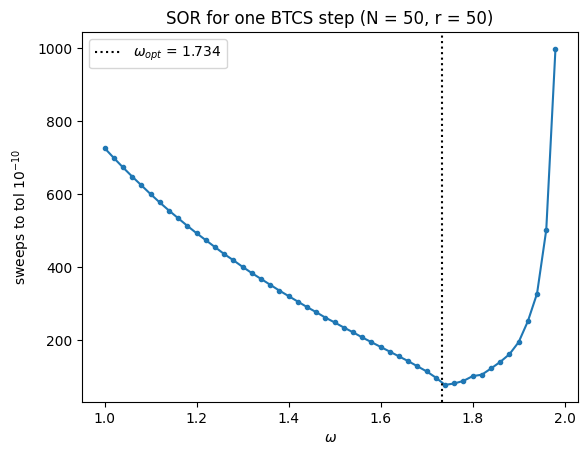

In [ ]:
# How sensitive is SOR to omega? (one BTCS step, N = 50, r = 50)
r = 50; ws = np.arange(1.0, 1.99, 0.02); ks = [solve_btcs_system(b, r, b, "sor", w)[1] for w in ws]
rhoJ = 2*r*np.cos(np.pi/N)/(1 + 2*r); wopt = 2/(1 + np.sqrt(1 - rhoJ**2))
plt.plot(ws, ks, "o-", ms=3); plt.axvline(wopt, color="k", ls=":", label=rf"$\omega_{{opt}}$ = {wopt:.3f}")
plt.xlabel(r"$\omega$"); plt.ylabel("sweeps to tol $10^{-10}$"); plt.title("SOR for one BTCS step (N = 50, r = 50)")
plt.legend(); plt.show()

### Observations: Jacobi, Gauss–Seidel, SOR
* For small $r$ (a few times the FTCS limit) Jacobi already needs only a modest number of sweeps per time step, because $A$ is strongly diagonally dominant and $\mathbf u^n$ is a good guess.
* As $r$ grows, $\rho_J\to1$: Jacobi slows down dramatically. Gauss–Seidel needs about half as many sweeps ($\rho_{GS}=\rho_J^2$), and SOR with $\omega_{opt}$ is an order of magnitude faster still.
* SOR is sensitive to $\omega$: near the optimum the sweep count drops sharply; too large an $\omega$ slows it down again.
* In 1D a **direct** tridiagonal solve (Thomas, `solve_banded`) is exact and costs $O(N)$ — always the best choice. Iterative methods become important for 2D and 3D problems, where direct solvers suffer from fill-in. That is the elliptic case below.

### Homework exercises
- Modify the grid size $N$ and compare the speed of convergence of Jacobi, Gauss–Seidel and SOR for BTCS. How does the number of sweeps scale with $N$ at fixed $\Delta t$?
- Try different boundary conditions:
    - **Neumann** (insulated end) with a ghost node: $u_{N+1}=u_{N-1}$, so the last row has $2$ in place of $1$ on the sub-diagonal.
    - **Mixed** (fixed temperature at one end, insulated at the other).
    - **Periodic** ($u_0=u_N$): the matrix becomes cyclic tridiagonal. Check that the total heat $\sum_iu_i$ is conserved.
- Verify the "magic" $r=1/6$ for FTCS on a different initial condition. Does it still give fourth order?
- Extend FTCS to two dimensions, $u_t=\alpha(u_{xx}+u_{yy})$. Use the zig-zag test to show that stability now requires $r\le\frac14$ (for $\Delta x=\Delta y$).

---
## 2. Elliptic PDE: Poisson and Laplace equations

**Poisson equation**:
$$-\nabla^2u=f(x,y),\qquad \nabla^2u=\frac{\partial^2u}{\partial x^2}+\frac{\partial^2u}{\partial y^2}\quad(\text{the Laplace operator})$$

**Laplace equation**:
$$\nabla^2u=0$$

**Where they appear**
* Steady heat conduction
* Electrostatics: $\nabla^2V=-\rho/\varepsilon_0$
* Steady diffusion, potential flow, elastic membranes.

**There is no time.** Every interior value depends only on **all** boundary values at once — we cannot march; we must solve for all unknowns **simultaneously**.

**Relevant boundary conditions** (needed on the whole closed boundary):
- Dirichlet: prescribed value, $u=g$
- Neumann: prescribed normal derivative (flux), $\partial u/\partial n=g$; insulated if $g=0$
- Periodic: $u$ repeats across opposite edges (bulk crystal, unit cell)

### Example problem: steady temperature in a square plate
* Unit square $0\le x,y\le1$, $\nabla^2T=0$.
* Top edge held at $T=100$; left, right and bottom edges at $T=0$.
* Exact solution (separation of variables, Fourier series):
$$T(x,y)=\frac{400}{\pi}\sum_{m=1,3,5,\dots}\frac{1}{m}\,\sin(m\pi x)\,\frac{\sinh(m\pi y)}{\sinh(m\pi)} .$$


In [ ]:
Tleft, Tright, Tbottom, Ttop = 0.0, 0.0, 0.0, 100.0

def plate_exact(x, y, M=401):
    "Fourier-series solution for the plate (top = 100, other edges = 0); overflow-safe form."
    x, y = np.broadcast_arrays(np.asarray(x, float), np.asarray(y, float))
    s = np.zeros_like(x)
    for m in range(1, M+1, 2):
        k = m*np.pi
        ratio = np.exp(k*(y - 1))*(1 - np.exp(-2*k*y))/(1 - np.exp(-2*k))   # sinh(ky)/sinh(k)
        s += 400/(np.pi*m)*np.sin(k*x)*ratio
    return s

print("exact T at the centre (0.5, 0.5):", plate_exact(0.5, 0.5))
print("exact T at (0.5, 0.25)          :", plate_exact(0.5, 0.25))

exact T at the centre (0.5, 0.5): 25.000000000000004
exact T at (0.5, 0.25)          : 9.541411796661341


### 2.1 The finite-difference grid
* $n\times n$ **interior** nodes, spacing $h=\Delta x=\Delta y=1/(n+1)$: $x_i=ih$, $y_j=jh$, $i,j=0,\dots,n+1$.
* Boundary nodes ($i$ or $j$ equal to $0$ or $n+1$) carry the known boundary temperatures.
* Unknowns are numbered row by row from the bottom ("natural ordering"): $k=(j-1)\,n+i$ for $i,j=1..n$.

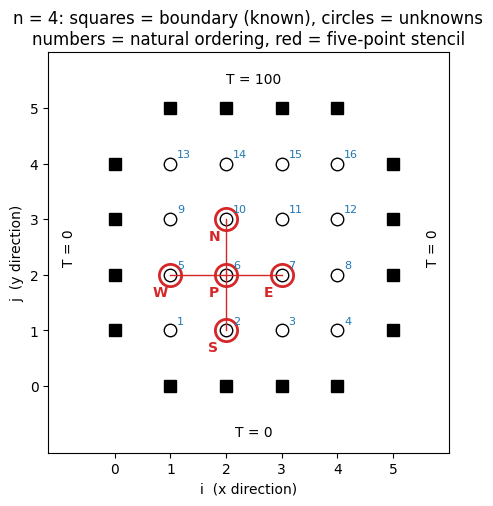

In [ ]:
def draw_plate_grid(n=4):
    fig, ax = plt.subplots(figsize=(5.2, 5.2))
    for j in range(n+2):
        for i in range(n+2):
            bnd = i in (0, n+1) or j in (0, n+1)
            if bnd and (i, j) in [(0, 0), (0, n+1), (n+1, 0), (n+1, n+1)]: continue   # corners not used
            ax.plot(i, j, "s" if bnd else "o", ms=9, mfc="k" if bnd else "w", mec="k")
            if not bnd: ax.text(i+0.12, j+0.12, str((j-1)*n + i), fontsize=8, color="tab:blue")
    P = (2, 2)
    for (di, dj, lab) in [(0, 0, "P"), (1, 0, "E"), (-1, 0, "W"), (0, 1, "N"), (0, -1, "S")]:
        ax.plot(P[0]+di, P[1]+dj, "o", ms=16, mfc="none", mec="tab:red", mew=2)
        ax.text(P[0]+di-0.32, P[1]+dj-0.38, lab, color="tab:red", fontsize=10, weight="bold")
    ax.plot([P[0]-1, P[0]+1], [P[1], P[1]], color="tab:red", lw=1); ax.plot([P[0], P[0]], [P[1]-1, P[1]+1], color="tab:red", lw=1)
    ax.set_xticks(range(n+2)); ax.set_yticks(range(n+2)); ax.set_xlabel("i  (x direction)"); ax.set_ylabel("j  (y direction)")
    ax.set_title(f"n = {n}: squares = boundary (known), circles = unknowns\nnumbers = natural ordering, red = five-point stencil")
    ax.text((n+1)/2, n+1.45, f"T = {Ttop:.0f}", ha="center"); ax.text((n+1)/2, -0.9, f"T = {Tbottom:.0f}", ha="center")
    ax.text(-0.95, (n+1)/2, f"T = {Tleft:.0f}", va="center", rotation=90); ax.text(n+1.6, (n+1)/2, f"T = {Tright:.0f}", va="center", rotation=90)
    ax.set_xlim(-1.2, n+2); ax.set_ylim(-1.2, n+2); ax.set_aspect("equal"); plt.show()

draw_plate_grid(4)

### 2.2 Central differences and the five-point formula

Central differences in $x$ and $y$ at node $P=(i,j)$:
$$\frac{u_{i+1,j}-2u_{i,j}+u_{i-1,j}}{\Delta x^2}+\frac{u_{i,j+1}-2u_{i,j}+u_{i,j-1}}{\Delta y^2}=-f_{i,j}\qquad(\text{truncation error }O(\Delta x^2)+O(\Delta y^2)).$$

For $\Delta x=\Delta y=h$ this is the **five-point formula**:
$$\boxed{4u_P-u_E-u_W-u_N-u_S=h^2f_P}\qquad\text{Laplace }(f=0):\quad u_P=\frac{u_E+u_W+u_N+u_S}{4}.$$
* For Laplace's equation, every node is the **average of its four neighbours**
* There can be no interior maximum or minimum: the hottest and coldest points lie on the boundary

#### Final discretized matrix form
Write the five-point formula for every unknown, and move known boundary values to the right-hand side:
$$S\,\mathbf u=\mathbf b,\qquad S=I\otimes K+K\otimes I,\qquad K=\mathrm{tridiag}(-1,2,-1)\ (n\times n),$$
where,
* $\otimes$ is the Kronecker product.
* Row $k$ of $S$ has $4$ on the diagonal and $-1$ for each interior neighbour
* $\mathbf b$ collects the boundary values next to node $k$ (plus $h^2f_k$)

#### Why this form?
* It says the 2D operator = 1D operator in $x$ + 1D operator in $y$.
* So the eigenvalues of $S$ are sums of the 1D eigenvalues of $K$: $\lambda_{pq}=\mu_p+\mu_q$, with $\mu_p=4\sin^2\frac{p\pi h}{2}$.
* This is where the eigenvalue and condition-number results below come from, and in code $S$ is one line with `sp.kron`.

#### Matrix properties
* **Symmetric**, and **sparse**: at most 5 non-zeros per row out of $n^2$.
* **Banded**: block tridiagonal with bandwidth $n$ (neighbours above and below are $n$ positions away). The band is *not* full, but direct LU fills it in.
* **Diagonally dominant** $\Rightarrow$ Jacobi and Gauss–Seidel converge.
* **Positive definite**: eigenvalues
* **Condition number** $\kappa_2=\lambda_{max}/\lambda_{min}\approx\dfrac{8}{2\pi^2h^2}=\dfrac{4}{\pi^2h^2}$ — grows like $1/h^2$ as the grid is refined.

#### Worked example: $n=2$ (4 unknowns)

**1: Five-point formula at each unknown.**
$$\begin{aligned}
\text{node }1:&\quad \phantom{-u_1+}4u_1-u_2-u_3\phantom{{}-u_4} = u_{0,1}+u_{1,0}+h^2f_1\\
\text{node }2:&\quad -u_1+4u_2\phantom{{}-u_3}-u_4 = u_{3,1}+u_{2,0}+h^2f_2\\
\text{node }3:&\quad -u_1\phantom{{}+4u_2}+4u_3-u_4 = u_{0,2}+u_{1,3}+h^2f_3\\
\text{node }4:&\quad \phantom{-u_1}-u_2-u_3+4u_4 = u_{3,2}+u_{2,3}+h^2f_4
\end{aligned}$$

**2: the same equations in matrix form:**
$$\underbrace{\begin{bmatrix}4&-1&-1&0\\-1&4&0&-1\\-1&0&4&-1\\0&-1&-1&4\end{bmatrix}}_{S}
\begin{bmatrix}u_1\\u_2\\u_3\\u_4\end{bmatrix}=
\underbrace{\begin{bmatrix}u_{0,1}+u_{1,0}+h^2f_1\\u_{3,1}+u_{2,0}+h^2f_2\\u_{0,2}+u_{1,3}+h^2f_3\\u_{3,2}+u_{2,3}+h^2f_4\end{bmatrix}}_{\mathbf b}$$

**3: build $S$ with Kronecker products.**

With $K=\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$ and $I=\begin{bmatrix}1&0\\0&1\end{bmatrix}$:

$$I\otimes K=\begin{bmatrix}1\cdot K&0\cdot K\\0\cdot K&1\cdot K\end{bmatrix}
=\begin{bmatrix}2&-1&0&0\\-1&2&0&0\\0&0&2&-1\\0&0&-1&2\end{bmatrix}
\qquad\leftarrow\ x\text{-direction: left–right neighbours in the same row}$$

$$K\otimes I=\begin{bmatrix}2I&-I\\-I&2I\end{bmatrix}
=\begin{bmatrix}2&0&-1&0\\0&2&0&-1\\-1&0&2&0\\0&-1&0&2\end{bmatrix}
\qquad\leftarrow\ y\text{-direction: up–down neighbours, } n \text{ positions apart}$$

$$I\otimes K+K\otimes I=\begin{bmatrix}4&-1&-1&0\\-1&4&0&-1\\-1&0&4&-1\\0&-1&-1&4\end{bmatrix}=S\ \checkmark$$

S for n = 3 (9 unknowns):
 [[ 4 -1  0 -1  0  0  0  0  0]
 [-1  4 -1  0 -1  0  0  0  0]
 [ 0 -1  4  0  0 -1  0  0  0]
 [-1  0  0  4 -1  0 -1  0  0]
 [ 0 -1  0 -1  4 -1  0 -1  0]
 [ 0  0 -1  0 -1  4  0  0 -1]
 [ 0  0  0 -1  0  0  4 -1  0]
 [ 0  0  0  0 -1  0 -1  4 -1]
 [ 0  0  0  0  0 -1  0 -1  4]]
b = [  0.   0.   0.   0.   0.   0. 100. 100. 100.]

n = 10: non-zeros = 460 of 10000 entries (4.6 %)
eigenvalues match the formula: True ;  cond = 48.4,  4/(pi^2 h^2) = 49.0


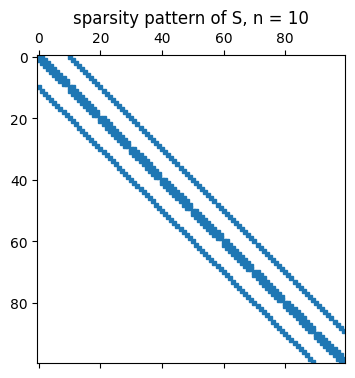

In [ ]:
def plate_system(n):
    "Sparse S (natural ordering k = j*n + i, 0-based) and right-hand side b for the plate problem."
    I = sp.identity(n, format="csr")
    K = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n), format="csr")
    S = (sp.kron(I, K) + sp.kron(K, I)).tocsr()
    B = np.zeros((n, n))                        # B[j, i]: boundary contributions next to node (i, j)
    B[:, 0] += Tleft; B[:, -1] += Tright; B[0, :] += Tbottom; B[-1, :] += Ttop
    return S, B.ravel()

S3, b3 = plate_system(3)
print("S for n = 3 (9 unknowns):\n", S3.toarray().astype(int))
print("b =", b3)

n = 10; S10, _ = plate_system(n)
lam = np.linalg.eigvalsh(S10.toarray())
h = 1/(n+1); p = np.arange(1, n+1)
lam_formula = np.sort((4*np.sin(p[:, None]*np.pi*h/2)**2 + 4*np.sin(p[None, :]*np.pi*h/2)**2).ravel())
print(f"\nn = {n}: non-zeros = {S10.nnz} of {n**4} entries ({100*S10.nnz/n**4:.1f} %)")
print("eigenvalues match the formula:", np.allclose(lam, lam_formula),
      f";  cond = {lam.max()/lam.min():.1f},  4/(pi^2 h^2) = {4/(np.pi**2*h**2):.1f}")
plt.figure(figsize=(4, 4)); plt.spy(S10, markersize=3); plt.title(f"sparsity pattern of S, n = {n}"); plt.show()

### 2.3 Direct solution
For moderate grids a sparse direct solver (`scipy.sparse.linalg.spsolve`) is the reference answer.

n = 31: T(0.5, 0.5) = 25.0000   (exact 25)


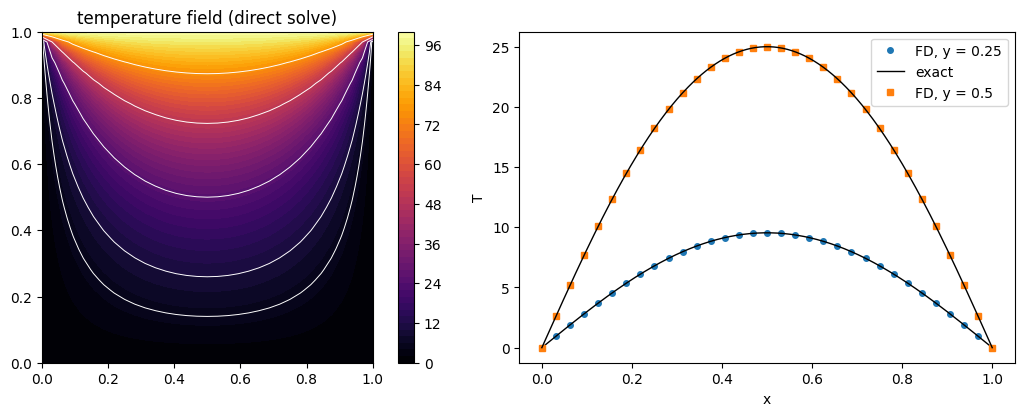

In [ ]:
def solve_direct(n):
    S, b = plate_system(n)
    u = spla.spsolve(S.tocsc(), b)
    G = np.zeros((n+2, n+2))                    # full grid including boundary, G[j, i]
    G[1:-1, 1:-1] = u.reshape(n, n)
    G[:, 0] = Tleft; G[:, -1] = Tright; G[0, :] = Tbottom; G[-1, :] = Ttop
    G[-1, 0] = G[-1, -1] = Ttop                 # corners only for plotting
    return G

n = 31; G = solve_direct(n); xg = np.linspace(0, 1, n+2)
print(f"n = {n}: T(0.5, 0.5) = {G[(n+1)//2, (n+1)//2]:.4f}   (exact 25)")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cs = ax[0].contourf(xg, xg, G, 50, cmap="inferno"); fig.colorbar(cs, ax=ax[0]); ax[0].set_aspect("equal")
ax[0].contour(xg, xg, G, [5, 10, 25, 50, 75], colors="w", linewidths=0.7); ax[0].set_title("temperature field (direct solve)")
j = (n+1)//4
ax[1].plot(xg, G[j, :], "o", ms=4, label="FD, y = 0.25"); ax[1].plot(xf, plate_exact(xf, 0.25), "k-", lw=1, label="exact")
ax[1].plot(xg, G[(n+1)//2, :], "s", ms=4, label="FD, y = 0.5"); ax[1].plot(xf, plate_exact(xf, 0.5), "k-", lw=1)
ax[1].set_xlabel("x"); ax[1].set_ylabel("T"); ax[1].legend(); plt.tight_layout(); plt.show()

### 2.4 Solving the Laplace equation with an iterative approach

* An iterative method needs an **initial guess** for the interior (e.g. $0$, or the average of the boundary values) and a **stopping criterion**.
* **Jacobi**: new value = average of the four **old** neighbours,
  $u_P^{(k+1)}=\frac14\big(u_E^{(k)}+u_W^{(k)}+u_N^{(k)}+u_S^{(k)}\big)$.
* **Gauss–Seidel**: sweep the grid and use **new** values as soon as they exist — simply overwrite in place. *(The earlier `Oct24` code updates `T[i, j]` in place, so it is in fact Gauss–Seidel.)*
* **SOR**: $u_P\leftarrow(1-\omega)u_P+\omega\,u_P^{GS}$; for this problem $\omega_{opt}=\dfrac{2}{1+\sin(\pi h)}$.
* **Stopping criterion**: the relative residual $\|\mathbf b-S\mathbf u\|_2/\|\mathbf b\|_2<\text{tol}$. (Stopping on a small *change* between sweeps can be misleading for slowly converging methods: small steps do not mean you are close.)

**Pseudo-algorithm (Gauss–Seidel / SOR on the grid)**
```text
set boundary values ; set interior to the initial guess
repeat (sweeps):
    for j = 1 .. n:                  # rows, from the bottom
        for i = 1 .. n:              # columns, left to right
            u_gs   = ( u[j,i+1] + u[j,i-1] + u[j+1,i] + u[j-1,i] ) / 4
            u[j,i] = (1 - omega)*u[j,i] + omega*u_gs      # omega = 1: Gauss-Seidel
    stop when relative residual < tol
```

In [ ]:
def new_grid(n, guess=0.0):
    G = np.full((n+2, n+2), guess)
    G[:, 0] = Tleft; G[:, -1] = Tright; G[0, :] = Tbottom; G[-1, :] = Ttop
    return G

def rel_residual(G, bnorm):
    R = 4*G[1:-1, 1:-1] - (G[1:-1, :-2] + G[1:-1, 2:] + G[:-2, 1:-1] + G[2:, 1:-1])   # = S u - b
    return np.linalg.norm(R)/bnorm

def laplace_iterative(n, method="gs", omega=1.0, tol=1e-6, max_sweeps=100000, snapshots=()):
    G = new_grid(n); bnorm = np.linalg.norm(plate_system(n)[1]); snaps = {}
    for k in range(1, max_sweeps+1):
        if method == "jacobi":                  # vectorized: all updates use old values
            G[1:-1, 1:-1] = 0.25*(G[1:-1, :-2] + G[1:-1, 2:] + G[:-2, 1:-1] + G[2:, 1:-1])
        else:                                   # Gauss-Seidel / SOR: in-place sweep
            for j in range(1, n+1):
                for i in range(1, n+1):
                    gs = 0.25*(G[j, i+1] + G[j, i-1] + G[j+1, i] + G[j-1, i])
                    G[j, i] = (1 - omega)*G[j, i] + omega*gs
        if k in snapshots: snaps[k] = G.copy()
        if rel_residual(G, bnorm) < tol:
            return G, k, snaps
    return G, max_sweeps, snaps

n = 15
Gj, kj, _ = laplace_iterative(n, "jacobi")
Gg, kg, _ = laplace_iterative(n, "gs")
wopt = 2/(1 + np.sin(np.pi/(n+1)))
Gs, ks, _ = laplace_iterative(n, "sor", omega=wopt)
Gd = solve_direct(n)
for name, Gx, k in [("Jacobi", Gj, kj), ("Gauss-Seidel", Gg, kg), (f"SOR (omega={wopt:.3f})", Gs, ks)]:
    print(f"{name:22s}: {k:5d} sweeps,  max difference from direct solve = {np.max(np.abs(Gx[1:-1,1:-1]-Gd[1:-1,1:-1])):.1e}")

Jacobi                :   571 sweeps,  max difference from direct solve = 6.2e-04
Gauss-Seidel          :   290 sweeps,  max difference from direct solve = 6.1e-04
SOR (omega=1.674)     :    44 sweeps,  max difference from direct solve = 2.2e-04


   n        h  Jacobi    G-S  omega_opt   SOR  rho_J = cos(pi h)
   7   0.1250     153     79      1.446    23            0.92388
  15   0.0625     571    290      1.674    44            0.98079
  31   0.0312    2076   1047      1.821    83            0.99518


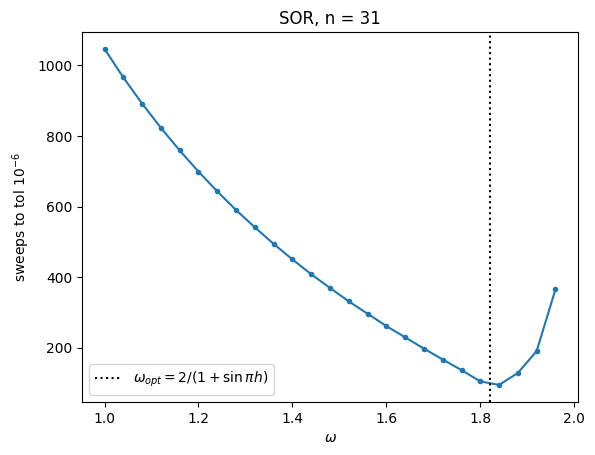

In [ ]:
# Comparison of the iterative methods as the grid is refined (tol = 1e-6)
print(f"{'n':>4} {'h':>8} {'Jacobi':>7} {'G-S':>6} {'omega_opt':>10} {'SOR':>5} {'rho_J = cos(pi h)':>18}")
for n in [7, 15, 31]:
    h = 1/(n+1); wopt = 2/(1 + np.sin(np.pi*h))
    kJ = laplace_iterative(n, "jacobi")[1]; kG = laplace_iterative(n, "gs")[1]; kS = laplace_iterative(n, "sor", wopt)[1]
    print(f"{n:4d} {h:8.4f} {kJ:7d} {kG:6d} {wopt:10.3f} {kS:5d} {np.cos(np.pi*h):18.5f}")

n = 31; ws = np.arange(1.0, 1.99, 0.04); ks = [laplace_iterative(n, "sor", w)[1] for w in ws]
plt.plot(ws, ks, "o-", ms=3); plt.axvline(2/(1+np.sin(np.pi/(n+1))), color="k", ls=":", label=r"$\omega_{opt}=2/(1+\sin\pi h)$")
plt.xlabel(r"$\omega$"); plt.ylabel("sweeps to tol $10^{-6}$"); plt.title(f"SOR, n = {n}"); plt.legend(); plt.show()

In [ ]:
# Animation: how the three methods build the solution, sweep by sweep (n = 31, initial guess 0)
n = 31; frames = sorted(set(np.unique(np.round(np.geomspace(1, 1500, 40)).astype(int))))
wopt = 2/(1 + np.sin(np.pi/(n+1)))
runs = {"Jacobi": laplace_iterative(n, "jacobi", tol=1e-12, max_sweeps=frames[-1], snapshots=frames)[2],
        "Gauss-Seidel": laplace_iterative(n, "gs", tol=1e-12, max_sweeps=frames[-1], snapshots=frames)[2],
        f"SOR, omega = {wopt:.2f}": laplace_iterative(n, "sor", wopt, tol=1e-12, max_sweeps=frames[-1], snapshots=frames)[2]}
Gref = solve_direct(n); bnorm = np.linalg.norm(plate_system(n)[1])
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
ims = []
for ax, (name, snaps) in zip(axs, runs.items()):
    im = ax.imshow(snaps[frames[0]], origin="lower", extent=[0, 1, 0, 1], cmap="inferno", vmin=0, vmax=100)
    ax.set_xticks([]); ax.set_yticks([]); ims.append((ax, name, im, snaps))
def update(f):
    k = frames[f]; out = []
    for ax, name, im, snaps in ims:
        kk = max(key for key in snaps if key <= k)      # SOR may converge before the last frame
        G = snaps[kk]; im.set_data(G)
        ax.set_title(f"{name}\nsweep {kk}: T(0.5,0.5) = {G[(n+1)//2, (n+1)//2]:.2f}, res = {rel_residual(G, bnorm):.0e}", fontsize=9)
        out.append(im)
    return out
anim = FuncAnimation(fig, update, frames=len(frames), interval=250); plt.close(fig); HTML(anim.to_jshtml())

### Observations: Jacobi, Gauss–Seidel and SOR for the plate
* All three converge to the direct solution (diagonally dominant, symmetric positive definite matrix).
* **Halving $h$ multiplies the sweep count by about 4 for Jacobi and Gauss–Seidel**, but only by about 2 for SOR. Reason: $\rho_J=\cos\pi h\approx1-\pi^2h^2/2$, so Jacobi needs $\propto1/h^2$ sweeps; $\rho_{GS}=\rho_J^2$ (half the sweeps); SOR with $\omega_{opt}$ has $\rho\approx1-2\pi h$, i.e. $\propto1/h$ sweeps.
* In the animation the heat "diffuses" in from the hot top edge. This is no coincidence: a **Jacobi sweep is exactly one FTCS time step of the 2D heat equation with $r=\tfrac14$** (the 2D stability limit). Iterating Jacobi = running the heat equation until it reaches steady state — and that takes long on a fine grid.
* SOR is sensitive to $\omega$; at $\omega_{opt}$ it needs tens of sweeps where Gauss–Seidel needs thousands.
* Iterative methods never form the matrix (only the stencil) and have no fill-in; a direct sparse solver is fast in 2D for moderate $n$, while large 3D problems rely on iterative (and multigrid / Krylov) methods.

### 2.5 Like the parabolic PDE, do consistency, stability and convergence apply to elliptic PDEs?

Yes — with "stability" meaning something slightly different, because there is no time marching.

* **Consistency**: inserting the exact solution into the five-point formula leaves $\tau=-\frac{h^2}{12}(u_{xxxx}+u_{yyyy})+O(h^4)\to0$.
* **Stability**: with $A_h=S/h^2$ the discrete version of $-\nabla^2$, the exact solution satisfies $A_h\mathbf u_{exact}=\mathbf f+\boldsymbol\tau$, so the error $\mathbf E=\mathbf u_{exact}-\mathbf u$ obeys $A_h\mathbf E=\boldsymbol\tau$. Stability means **$\|A_h^{-1}\|$ stays bounded as $h\to0$**. Here $\|A_h^{-1}\|_2=1/\lambda_{min}(A_h)$ and $\lambda_{min}(A_h)=\frac{8}{h^2}\sin^2\frac{\pi h}{2}\to2\pi^2$.
* **Convergence** follows (the elliptic analogue of Lax):
$$\|\mathbf E\|\le\|A_h^{-1}\|\,\|\boldsymbol\tau\|\approx\frac{1}{2\pi^2}\,O(h^2)\to0.$$

**Two different kinds of "convergence" — do not mix them up**
1. **Iterative convergence** ($k\to\infty$, fixed grid): the solver approaches the *discrete* solution. Governed by $\rho(T)$ of Jacobi/Gauss–Seidel/SOR.
2. **Discretization convergence** ($h\to0$): the discrete solution approaches the *exact* PDE solution. Governed by consistency + stability.

Total error = iteration error + discretization error. **Iterating far beyond the discretization error is wasted work.**

In [ ]:
# (a) stability: ||A_h^{-1}||_2 stays bounded;  (b) discretization error at (0.5, 0.25) falls like h^2
exact_q = plate_exact(0.5, 0.25)
print(f"{'n':>4} {'h':>8} {'||A_h^-1||_2':>13} {'T(0.5,0.25)':>12} {'error':>9}")
for n in [3, 7, 15, 31, 63]:
    h = 1/(n+1); lam_min = 8/h**2*np.sin(np.pi*h/2)**2
    G = solve_direct(n); val = G[(n+1)//4, (n+1)//2]
    print(f"{n:4d} {h:8.4f} {1/lam_min:13.5f} {val:12.4f} {abs(val-exact_q):9.2e}")
print(f"limit 1/(2 pi^2) = {1/(2*np.pi**2):.5f}")

# (c) iteration error vs discretization error: SOR on n = 31 with decreasing tolerance
n = 31; wopt = 2/(1 + np.sin(np.pi/(n+1))); Gd = solve_direct(n)
print(f"\nn = {n}: discretization error at (0.5, 0.25) = {abs(Gd[(n+1)//4, (n+1)//2]-exact_q):.2e}")
for tol in [1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-8]:
    G, k, _ = laplace_iterative(n, "sor", wopt, tol=tol)
    print(f"tol = {tol:.0e}: {k:4d} sweeps, error vs exact = {abs(G[(n+1)//4, (n+1)//2]-exact_q):.2e}, "
          f"error vs discrete = {abs(G[(n+1)//4, (n+1)//2]-Gd[(n+1)//4, (n+1)//2]):.1e}")

   n        h  ||A_h^-1||_2  T(0.5,0.25)     error
   3   0.2500       0.05335       9.8214  2.80e-01
   7   0.1250       0.05132       9.6273  8.59e-02
  15   0.0625       0.05082       9.5642  2.28e-02
  31   0.0312       0.05070       9.5472  5.80e-03
  63   0.0156       0.05067       9.5429  1.46e-03
limit 1/(2 pi^2) = 0.05066

n = 31: discretization error at (0.5, 0.25) = 5.80e-03
tol = 1e-01:   20 sweeps, error vs exact = 9.54e+00, error vs discrete = 9.5e+00
tol = 1e-02:   44 sweeps, error vs exact = 3.34e-01, error vs discrete = 3.4e-01
tol = 1e-03:   61 sweeps, error vs exact = 1.86e-02, error vs discrete = 2.4e-02
tol = 1e-04:   65 sweeps, error vs exact = 4.91e-03, error vs discrete = 1.1e-02
tol = 1e-06:   83 sweeps, error vs exact = 5.35e-03, error vs discrete = 4.5e-04
tol = 1e-08:  117 sweeps, error vs exact = 5.80e-03, error vs discrete = 7.1e-07


### Observations
* $\|A_h^{-1}\|_2$ decreases towards $1/(2\pi^2)\approx0.0507$ and never grows as $h\to0$: the five-point scheme is **stable**.
* The error at $(0.5,0.25)$ falls by about 4 each time $h$ is halved: second-order **convergence**, as consistency + stability predict.
* With a loose tolerance the **iteration error** dominates. Once it drops below the discretization error (here around $10^{-3}$–$10^{-4}$ in the residual), the error compared with the exact solution stops improving: further sweeps only reproduce the discrete solution more precisely, not the true temperature.

### Homework exercises (elliptic)
- Change the boundary temperatures (e.g. $0,100,200,0$ as in the practice problem set) and check the centre value against the symmetry argument.
- Make one edge **insulated** using ghost nodes. How do the corresponding rows of $S$ change? Is $S$ still symmetric?
- Solve the **Poisson** equation $-\nabla^2u=1$ with $u=0$ on all edges (steady heating of a plate). Where is the maximum?
- Run the 2D FTCS heat equation with $r=\frac14$ from $u=0$ and verify that it reproduces the Jacobi iterates sweep by sweep.

---
## 3. Summary: numerical solution of parabolic and elliptic PDEs

**Parabolic (heat / diffusion equation) — march in time**

| scheme | type | truncation error | stability ($r=\alpha\Delta t/\Delta x^2$) | cost per step | remarks |
|---|---|---|---|---|---|
| FTCS | explicit | $O(\Delta t)+O(\Delta x^2)$ | $r\le\frac12$ | $O(N)$, no solve | zig-zag blow-up for $r>\frac12$; $r=\frac16$ gives extra accuracy |
| BTCS | implicit | $O(\Delta t)+O(\Delta x^2)$ | any $r$ | tridiagonal solve | never oscillates; inaccurate for large $\Delta t$ |
| Crank–Nicolson | implicit | $O(\Delta t^2)+O(\Delta x^2)$ | any $r$ | tridiagonal solve | most accurate; wiggles for sharp data and large $r$ |

**Elliptic (Laplace / Poisson) — solve for everything at once**

| method | sweeps to converge | remarks |
|---|---|---|
| direct sparse LU | — | exact up to round-off; fill-in grows with grid size |
| Jacobi | $\propto 1/h^2$ | simplest; = FTCS heat equation with $r=\frac14$ |
| Gauss–Seidel | $\propto 1/h^2$ (half of Jacobi) | in-place update |
| SOR, $\omega_{opt}=2/(1+\sin\pi h)$ | $\propto 1/h$ | much faster; sensitive to $\omega$ |

**Key concepts**
* **Local truncation error** (one step) vs **global error** (accumulated); the global error has the order of $\tau$ only for a stable scheme.
* **Consistency** ($\tau\to0$) + **stability** (errors not amplified) $\iff$ **convergence** (Lax equivalence theorem).
* **Von Neumann analysis**: a linear scheme multiplies each grid wave by $G(\theta)$; stable iff $|G|\le1$ for all $\theta$. The zig-zag wave ($\theta=\pi$) is usually the dangerous one.
* **Diffusion number** $r\le\frac12$ means $\Delta t\propto\Delta x^2$ for explicit schemes — the reason implicit schemes are standard for diffusion.
* Implicit schemes and elliptic problems lead to **sparse, symmetric, diagonally dominant** linear systems: tridiagonal in 1D (Thomas), banded in 2D (sparse direct or iterative solvers).
* For iterative solvers, distinguish **iterative convergence** (solver → discrete solution) from **discretization convergence** (discrete solution → PDE solution).